In [1]:
import sys
import torch
import numpy as np
import pandas as pd

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

Python: f:\New folder\envs\gpuenv\python.exe
PyTorch: 2.11.0+cu128
GPU Available: True


In [2]:
import torch
import torchvision

import timm
import albumentations as A

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("All imports successful!")
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Timm:", timm.__version__)

f:\New folder\envs\gpuenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All imports successful!
PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
Timm: 1.0.29


In [3]:
import sys
print(sys.executable)

f:\New folder\envs\gpuenv\python.exe


In [4]:
import sys

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

Python executable:
f:\New folder\envs\gpuenv\python.exe

Python version:
3.11.16 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:36:16) [MSC v.1942 64 bit (AMD64)]


In [5]:
import torch

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())
print("CUDA Version:", torch.version.cuda)

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("GPU Count:", torch.cuda.device_count())
else:
    print("GPU Not Detected!")

PyTorch Version: 2.11.0+cu128
CUDA Available: True
CUDA Version: 12.8
GPU Name: NVIDIA RTX 4500 Ada Generation
GPU Count: 1


In [6]:
import os
!pip install albumentations timm
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
import albumentations as A
import timm
torch.backends.cudnn.benchmark = True
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import datasets, models
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

DATA_DIR="Fabric-Own/"
IMG_SIZE=299
BATCH_SIZE=8
EPOCHS=50
PATIENCE=10
LEARNING_RATE=1e-4
WEIGHT_DECAY=1e-4
DEVICE="cuda" if torch.cuda.is_available() else "cpu"
print("Using:",DEVICE)

SEED=42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark=True

Using: cuda


In [7]:
from albumentations.pytorch import ToTensorV2

**Attention note:** CBAM (channel + spatial attention) is added to every pure-CNN backbone below (ResNet50, EfficientNet-B3, MobileNetV3, Xception, ConvNeXt-Tiny, DenseNet121) right after each model is built. ViT-Base and Swin-Tiny are left unchanged — they already use self-attention internally as transformers, and their feature maps are token sequences rather than spatial CxHxW maps, so CBAM doesn't apply the same way. HybridWeaveNet already has its own `DualAttention` block built in.

In [8]:
# ---- Shared attention utilities (used by ResNet50, EfficientNetB3, MobileNetV3,
#      Xception, ConvNeXt-Tiny, DenseNet121, and HybridWeaveNet below) ----

class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        hidden_channels = max(channels // reduction, 1)
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.mlp = nn.Sequential(
            nn.Conv2d(channels, hidden_channels, kernel_size=1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden_channels, channels, kernel_size=1, bias=False),
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_attention = self.mlp(self.avg_pool(x))
        max_attention = self.mlp(self.max_pool(x))
        attention = self.sigmoid(avg_attention + max_attention)
        return x * attention


class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        padding = kernel_size // 2
        self.conv = nn.Conv2d(2, 1, kernel_size=kernel_size, padding=padding, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_features = torch.mean(x, dim=1, keepdim=True)
        max_features, _ = torch.max(x, dim=1, keepdim=True)
        spatial_features = torch.cat([avg_features, max_features], dim=1)
        attention = self.sigmoid(self.conv(spatial_features))
        return x * attention


class DualAttention(nn.Module):
    """CBAM-style: channel attention, then spatial attention."""
    def __init__(self, channels, reduction=16, spatial_kernel=7):
        super().__init__()
        self.channel_attention = ChannelAttention(channels=channels, reduction=reduction)
        self.spatial_attention = SpatialAttention(kernel_size=spatial_kernel)

    def forward(self, x):
        x = self.channel_attention(x)
        x = self.spatial_attention(x)
        return x


def attach_attention(model, target_module, channels, reduction=16, spatial_kernel=7):
    """
    Attaches a DualAttention (CBAM) block right after target_module's output,
    via a forward hook. Registered as model.dual_attention, so it's automatically
    included in model.parameters() (trains normally) and model.to(DEVICE)/state_dict().
    """
    model.dual_attention = DualAttention(channels=channels, reduction=reduction, spatial_kernel=spatial_kernel)

    def hook(module, inputs, output):
        return model.dual_attention(output)

    target_module.register_forward_hook(hook)
    return model


In [9]:
train_transform=A.Compose([
    A.Resize(IMG_SIZE,IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=20,p=0.5),
    A.ColorJitter(brightness=0.2,contrast=0.2,saturation=0.2,hue=0.1,p=0.5),
    A.OneOf([
        A.GaussianBlur(blur_limit=(3,7),p=1.0),
        A.MotionBlur(blur_limit=5,p=1.0)
    ],p=0.2),
    A.OneOf([
        A.CoarseDropout(p=1.0),
        A.GridDropout(ratio=0.2,p=1.0)
    ],p=0.3),
    A.Normalize(mean=(0.485,0.456,0.406),std=(0.229,0.224,0.225)),
    ToTensorV2()
])

val_transform=A.Compose([
    A.Resize(IMG_SIZE,IMG_SIZE),
    A.Normalize(mean=(0.485,0.456,0.406),std=(0.229,0.224,0.225)),
    ToTensorV2()
])

In [10]:
class FabricDataset(Dataset):
    def __init__(self,root,indices,transform=None):
        self.dataset=datasets.ImageFolder(root)
        self.indices=indices
        self.transform=transform
        self.classes=self.dataset.classes
        self.samples=self.dataset.samples
    def __len__(self):
        return len(self.indices)
    def __getitem__(self,idx):
        real_idx=self.indices[idx]
        image_path,label=self.samples[real_idx]
        image=self.dataset.loader(image_path)
        image=np.array(image)
        if self.transform:
            image=self.transform(image=image)["image"]
        return image,label

In [12]:
DATA_DIR = r"F:\project\Fabric-Own"
base_dataset = datasets.ImageFolder(DATA_DIR)

class_names = base_dataset.classes
num_classes = len(class_names)

print("Classes:", class_names)
print("Total images:", len(base_dataset))

from sklearn.model_selection import train_test_split

indices = np.arange(len(base_dataset))

all_targets = [s[1] for s in base_dataset.samples]
train_indices, temp_indices = train_test_split(
    indices, test_size=0.4, stratify=all_targets, random_state=SEED
)
temp_targets = [base_dataset.samples[i][1] for i in temp_indices]
val_indices, test_indices = train_test_split(
    temp_indices, test_size=0.5, stratify=temp_targets, random_state=SEED
)

print("Train:", len(train_indices))
print("Validation:", len(val_indices))
print("Test:", len(test_indices))

Classes: ['Banarasi', 'Bandhani', 'Chanderi', 'Kanjeevaram', 'Khadi', 'Patola', 'Tussar']
Total images: 2596
Train: 1557
Validation: 519
Test: 520


In [13]:
train_ds=FabricDataset(DATA_DIR,train_indices,train_transform)
val_ds=FabricDataset(DATA_DIR,val_indices,val_transform)
test_ds=FabricDataset(DATA_DIR,test_indices,val_transform)

In [14]:
train_targets=[base_dataset.samples[i][1] for i in train_indices]
class_count=np.bincount(train_targets,minlength=num_classes)
print("Class count:",class_count)

class_weights=1.0/class_count
sample_weights=[class_weights[label] for label in train_targets]
sample_weights=torch.DoubleTensor(sample_weights)

sampler=WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

Class count: [240 240 179 240 179 240 239]


In [15]:
train_loader=DataLoader(train_ds,batch_size=BATCH_SIZE,sampler=sampler,num_workers=0)
val_loader=DataLoader(val_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)
test_loader=DataLoader(test_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)

In [16]:
def mixup_data(images,labels,alpha=0.4):
    lam=np.random.beta(alpha,alpha) if alpha>0 else 1.0
    batch_size=images.size(0)
    index=torch.randperm(batch_size).to(images.device)
    mixed_images=lam*images+(1-lam)*images[index]
    labels_a=labels
    labels_b=labels[index]
    return mixed_images,labels_a,labels_b,lam

def mixup_criterion(criterion,prediction,y_a,y_b,lam):
    return lam*criterion(prediction,y_a)+(1-lam)*criterion(prediction,y_b)

In [17]:
def rand_bbox(size,lam):
    W=size[3]
    H=size[2]
    cut_rat=np.sqrt(1.0-lam)
    cut_w=int(W*cut_rat)
    cut_h=int(H*cut_rat)
    cx=np.random.randint(W)
    cy=np.random.randint(H)
    bbx1=np.clip(cx-cut_w//2,0,W)
    bby1=np.clip(cy-cut_h//2,0,H)
    bbx2=np.clip(cx+cut_w//2,0,W)
    bby2=np.clip(cy+cut_h//2,0,H)
    return bbx1,bby1,bbx2,bby2

def cutmix_data(images,labels,alpha=1.0):
    lam=np.random.beta(alpha,alpha)
    batch_size=images.size(0)
    index=torch.randperm(batch_size).to(images.device)
    bbx1,bby1,bbx2,bby2=rand_bbox(images.size(),lam)
    images[:,:,bby1:bby2,bbx1:bbx2]=images[index,:,bby1:bby2,bbx1:bbx2]
    area=(bbx2-bbx1)*(bby2-bby1)
    lam=1-area/(images.size(2)*images.size(3))
    labels_a=labels
    labels_b=labels[index]
    return images,labels_a,labels_b,lam

In [18]:
class ModelEMA:
    def __init__(self,model,decay=0.999):
        self.ema=copy.deepcopy(model).eval()
        self.decay=decay
        for p in self.ema.parameters():
            p.requires_grad_(False)
    @torch.no_grad()
    def update(self,model):
        ema_state=self.ema.state_dict()
        model_state=model.state_dict()
        for key in ema_state.keys():
            if ema_state[key].dtype.is_floating_point:
                ema_state[key].mul_(self.decay).add_(model_state[key],alpha=1-self.decay)
            else:
                ema_state[key].copy_(model_state[key])

In [19]:
def train_model(model,name):
    model=model.to(DEVICE)
    class_weights_t = torch.tensor(1.0/class_count, dtype=torch.float32).to(DEVICE)
    class_weights_t = class_weights_t / class_weights_t.sum() * num_classes
    class FocalLoss(nn.Module):
        def __init__(self, alpha=None, gamma=2.0, label_smoothing=0.1):
            super().__init__()
            self.gamma = gamma
            self.ce = nn.CrossEntropyLoss(weight=alpha, label_smoothing=label_smoothing, reduction='none')
        def forward(self, outputs, targets):
            ce_loss = self.ce(outputs, targets)
            pt = torch.exp(-ce_loss)
            return ((1-pt)**self.gamma * ce_loss).mean()

    criterion = FocalLoss(alpha=class_weights_t, gamma=2.0, label_smoothing=0.1)
    optimizer=optim.AdamW(model.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
    scheduler=optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=3)
    ema=ModelEMA(model,decay=0.999)
    train_losses=[]
    val_losses=[]
    val_accuracies=[]
    best_val_acc=0.0
    best_weights=copy.deepcopy(model.state_dict())
    best_ema_weights=copy.deepcopy(ema.ema.state_dict())
    patience_counter=0

    for epoch in range(EPOCHS):
        model.train()
        running_loss=0.0
        correct=0
        total=0

        for images,labels in train_loader:
            images=images.to(DEVICE,non_blocking=True)
            labels=labels.to(DEVICE,non_blocking=True)
            optimizer.zero_grad()

            if epoch<int(EPOCHS*0.7):
                r=np.random.rand()
                if r<0.25:
                    images,labels_a,labels_b,lam=mixup_data(images,labels)
                    outputs=model(images)
                    loss=mixup_criterion(criterion,outputs,labels_a,labels_b,lam)
                elif r<0.50:
                    images,labels_a,labels_b,lam=cutmix_data(images,labels)
                    outputs=model(images)
                    loss=mixup_criterion(criterion,outputs,labels_a,labels_b,lam)
                else:
                    outputs=model(images)
                    loss=criterion(outputs,labels)
            else:
                outputs=model(images)
                loss=criterion(outputs,labels)

            loss.backward()
            optimizer.step()
            ema.update(model)

            running_loss+=loss.item()
            _,preds=torch.max(outputs,1)
            correct+=(preds==labels).sum().item()
            total+=labels.size(0)

        train_loss=running_loss/len(train_loader)
        train_acc=correct/total
        train_losses.append(train_loss)

        ema.ema.eval()
        val_loss=0.0
        correct=0
        total=0

        with torch.no_grad():
            for images,labels in val_loader:
                images=images.to(DEVICE,non_blocking=True)
                labels=labels.to(DEVICE,non_blocking=True)
                outputs=ema.ema(images)
                loss=criterion(outputs,labels)
                val_loss+=loss.item()
                _,preds=torch.max(outputs,1)
                correct+=(preds==labels).sum().item()
                total+=labels.size(0)

        val_loss/=len(val_loader)
        val_acc=correct/total
        val_losses.append(val_loss)
        val_accuracies.append(val_acc)
        scheduler.step(val_acc)

        print(f"{name} | Epoch {epoch+1:02d}/{EPOCHS} | Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

        if val_acc>best_val_acc:
            best_val_acc=val_acc
            best_weights=copy.deepcopy(model.state_dict())
            best_ema_weights=copy.deepcopy(ema.ema.state_dict())
            patience_counter=0
        else:
            patience_counter+=1

        if patience_counter>=PATIENCE:
            print(f"Early stopping at epoch {epoch+1}")
            break

    model.load_state_dict(best_weights)
    ema.ema.load_state_dict(best_ema_weights)

    print(f"Best validation accuracy for {name}: {best_val_acc:.4f}")
    return model,ema.ema,train_losses,val_losses,val_accuracies

In [20]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score, roc_auc_score
from sklearn.manifold import TSNE

In [21]:
def extract_features(model,loader):
    model.eval()
    features=[]
    labels=[]

    with torch.no_grad():
        for images,target in loader:
            images=images.to(DEVICE)

            if hasattr(model,"backbone") and hasattr(model,"gap") and hasattr(model,"dual_attention"):
                x=model.backbone.forward_features(images)
                x=model.dual_attention(x)
                x=model.gap(x)
                x=torch.flatten(x,1)
            elif hasattr(model,"forward_features"):
                x=model.forward_features(images)
                if x.dim()==4:
                    x=torch.mean(x,dim=(2,3))
                elif x.dim()==3:
                    x=torch.mean(x,dim=1)
            else:
                x=model(images)

            features.append(x.cpu().numpy())
            labels.extend(target.numpy())

    features=np.concatenate(features,axis=0)
    labels=np.array(labels)

    return features,labels

# MODEL EVALUATION

In [22]:
def evaluate_model(model,name):
    model.eval()
    y_true=[]
    y_pred=[]
    y_prob=[]

    tta_transforms = [
        lambda x: x,
        lambda x: torch.flip(x, dims=[3]),
    ]

    with torch.no_grad():
        for images,labels in test_loader:
            images=images.to(DEVICE)

            probs_sum=0
            for t in tta_transforms:
                outputs=model(t(images))
                probs_sum+=torch.softmax(outputs,dim=1)
            probabilities=probs_sum/len(tta_transforms)
            preds=torch.argmax(probabilities,dim=1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
            y_prob.extend(probabilities.cpu().numpy())

    y_true=np.array(y_true)
    y_pred=np.array(y_pred)
    y_prob=np.array(y_prob)

    print(f"\n{name} Classification Report:")
    print(classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4,
        zero_division=0
    ))

    acc=accuracy_score(y_true,y_pred)
    prec=precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )
    rec=recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )
    f1=f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    print(f"{name} Accuracy  : {acc:.4f}")
    print(f"{name} Precision : {prec:.4f}")
    print(f"{name} Recall    : {rec:.4f}")
    print(f"{name} F1-Score  : {f1:.4f}")

    # ============================================================
    # 1. CONFUSION MATRIX
    # ============================================================

    cm=confusion_matrix(
        y_true,
        y_pred
    )

    plt.figure(figsize=(9,8))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(
        f"{name} - Confusion Matrix"
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.tight_layout()
    plt.show()

    # ============================================================
    # 2. MULTICLASS ROC CURVE - ONE VS REST
    # ============================================================

    n_classes=len(class_names)

    y_true_bin=label_binarize(
        y_true,
        classes=np.arange(n_classes)
    )

    fpr={}
    tpr={}
    roc_auc={}

    for i in range(n_classes):
        fpr[i],tpr[i],_=roc_curve(
            y_true_bin[:,i],
            y_prob[:,i]
        )

        roc_auc[i]=auc(
            fpr[i],
            tpr[i]
        )

    all_fpr=np.unique(
        np.concatenate([
            fpr[i]
            for i in range(n_classes)
        ])
    )

    mean_tpr=np.zeros_like(
        all_fpr
    )

    for i in range(n_classes):
        mean_tpr+=np.interp(
            all_fpr,
            fpr[i],
            tpr[i]
        )

    mean_tpr/=n_classes

    macro_auc=auc(
        all_fpr,
        mean_tpr
    )

    micro_fpr,micro_tpr,_=roc_curve(
        y_true_bin.ravel(),
        y_prob.ravel()
    )

    micro_auc=auc(
        micro_fpr,
        micro_tpr
    )

    weighted_auc=roc_auc_score(
        y_true_bin,
        y_prob,
        average="weighted",
        multi_class="ovr"
    )

    plt.figure(figsize=(10,8))

    for i in range(n_classes):
        plt.plot(
            fpr[i],
            tpr[i],
            linewidth=1.5,
            label=f"{class_names[i]} AUC={roc_auc[i]:.4f}"
        )

    plt.plot(
        micro_fpr,
        micro_tpr,
        linestyle="--",
        linewidth=2.5,
        label=f"Micro-average AUC={micro_auc:.4f}"
    )

    plt.plot(
        all_fpr,
        mean_tpr,
        linestyle=":",
        linewidth=3,
        label=f"Macro-average AUC={macro_auc:.4f}"
    )

    plt.plot(
        [0,1],
        [0,1],
        linestyle="--",
        linewidth=1
    )

    plt.xlim(0,1)
    plt.ylim(0,1.05)

    plt.xlabel(
        "False Positive Rate"
    )

    plt.ylabel(
        "True Positive Rate"
    )

    plt.title(
        f"{name} - Multiclass ROC Curve (OvR)"
    )

    plt.legend(
        loc="lower right",
        fontsize=8
    )

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()
    plt.show()

    print(f"\n{name} ROC-AUC:")
    for i in range(n_classes):
        print(
            f"{class_names[i]}: "
            f"{roc_auc[i]:.4f}"
        )

    print(
        f"Macro AUC: {macro_auc:.4f}"
    )

    print(
        f"Micro AUC: {micro_auc:.4f}"
    )

    print(
        f"Weighted AUC: {weighted_auc:.4f}"
    )

    # ============================================================
    # 3. PRECISION-RECALL CURVE - ONE VS REST
    # ============================================================

    precision={}
    recall={}
    average_precision={}

    for i in range(n_classes):
        precision[i],recall[i],_=precision_recall_curve(
            y_true_bin[:,i],
            y_prob[:,i]
        )

        average_precision[i]=average_precision_score(
            y_true_bin[:,i],
            y_prob[:,i]
        )

    micro_precision,micro_recall,_=precision_recall_curve(
        y_true_bin.ravel(),
        y_prob.ravel()
    )

    micro_ap=average_precision_score(
        y_true_bin,
        y_prob,
        average="micro"
    )

    macro_ap=average_precision_score(
        y_true_bin,
        y_prob,
        average="macro"
    )

    weighted_ap=average_precision_score(
        y_true_bin,
        y_prob,
        average="weighted"
    )

    plt.figure(figsize=(10,8))

    for i in range(n_classes):
        plt.plot(
            recall[i],
            precision[i],
            linewidth=1.5,
            label=f"{class_names[i]} AP={average_precision[i]:.4f}"
        )

    plt.plot(
        micro_recall,
        micro_precision,
        linestyle="--",
        linewidth=2.5,
        label=f"Micro-average AP={micro_ap:.4f}"
    )

    plt.xlabel(
        "Recall"
    )

    plt.ylabel(
        "Precision"
    )

    plt.title(
        f"{name} - Precision-Recall Curve (OvR)"
    )

    plt.xlim(0,1)
    plt.ylim(0,1.05)

    plt.legend(
        loc="lower left",
        fontsize=8
    )

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()
    plt.show()

    print(f"\n{name} Average Precision:")
    for i in range(n_classes):
        print(
            f"{class_names[i]}: "
            f"{average_precision[i]:.4f}"
        )

    print(
        f"Macro AP: {macro_ap:.4f}"
    )

    print(
        f"Micro AP: {micro_ap:.4f}"
    )

    print(
        f"Weighted AP: {weighted_ap:.4f}"
    )

    # ============================================================
    # 4. t-SNE FEATURE REPRESENTATIONS
    # ============================================================

    features,feature_labels=extract_features(
        model,
        test_loader
    )

    print(
        f"\n{name} Feature Shape: "
        f"{features.shape}"
    )

    tsne=TSNE(
        n_components=2,
        perplexity=30,
        learning_rate="auto",
        init="pca",
        random_state=42
    )

    features_2d=tsne.fit_transform(
        features
    )

    plt.figure(figsize=(10,8))

    for i,class_name in enumerate(class_names):
        mask=feature_labels==i

        plt.scatter(
            features_2d[mask,0],
            features_2d[mask,1],
            s=25,
            alpha=0.7,
            label=class_name
        )

    plt.xlabel(
        "t-SNE Dimension 1"
    )

    plt.ylabel(
        "t-SNE Dimension 2"
    )

    plt.title(
        f"{name} - t-SNE Feature Representation"
    )

    plt.legend(
        bbox_to_anchor=(1.05,1),
        loc="upper left"
    )

    plt.grid(
        alpha=0.2
    )

    plt.tight_layout()
    plt.show()

    return {
        "accuracy":acc,
        "precision":prec,
        "recall":rec,
        "f1":f1,
        "macro_auc":macro_auc,
        "micro_auc":micro_auc,
        "weighted_auc":weighted_auc,
        "macro_ap":macro_ap,
        "micro_ap":micro_ap,
        "weighted_ap":weighted_ap,
        "class_auc":roc_auc,
        "class_ap":average_precision,
        "confusion_matrix":cm,
        "features":features,
        "feature_labels":feature_labels,
        "tsne_features":features_2d
    }

# DATASET DESCRIPTION


In [23]:
import pandas as pd

train_targets = [base_dataset.samples[i][1] for i in train_indices]
val_targets   = [base_dataset.samples[i][1] for i in val_indices]
test_targets  = [base_dataset.samples[i][1] for i in test_indices]
all_targets   = [s[1] for s in base_dataset.samples]

rows = []
for idx, cname in enumerate(class_names):
    total = all_targets.count(idx)
    train_c = train_targets.count(idx)
    val_c = val_targets.count(idx)
    test_c = test_targets.count(idx)
    rows.append([cname, total, train_c, val_c, test_c])

data_description = pd.DataFrame(
    rows, columns=["Class", "Total Images", "Training", "Validation", "Testing"]
)

totals_row = pd.DataFrame([[
    "TOTAL",
    data_description["Total Images"].sum(),
    data_description["Training"].sum(),
    data_description["Validation"].sum(),
    data_description["Testing"].sum(),
]], columns=data_description.columns)

data_description = pd.concat([data_description, totals_row], ignore_index=True)

print(data_description.to_string(index=False))

data_description.to_csv("data_description.csv", index=False)

      Class  Total Images  Training  Validation  Testing
   Banarasi           400       240          80       80
   Bandhani           400       240          80       80
   Chanderi           298       179          59       60
Kanjeevaram           400       240          80       80
      Khadi           299       179          60       60
     Patola           400       240          80       80
     Tussar           399       239          80       80
      TOTAL          2596      1557         519      520


In [24]:
import os
import shutil
import pandas as pd

# ---- Step 1: Build per-class test DataFrames ----
class_test_dfs = {}

for cname in class_names:
    class_label = class_names.index(cname)
    rows = []
    for idx in test_indices:
        filepath, label = base_dataset.samples[idx]
        if label == class_label:
            rows.append([os.path.basename(filepath), filepath])
    df = pd.DataFrame(rows, columns=["Filename", "Full Path"]).sort_values("Filename").reset_index(drop=True)
    class_test_dfs[cname] = df

print("class_test_dfs created for:", list(class_test_dfs.keys()))

# ---- Step 2: Copy images into test_cases/<ClassName>/ ----
output_root = os.path.abspath("test_cases")
print("\nImages will be copied to:", output_root)

os.makedirs(output_root, exist_ok=True)

copied_count = 0
missing_count = 0

for cname in class_names:
    class_folder = os.path.join(output_root, cname)
    os.makedirs(class_folder, exist_ok=True)
    for _, row in class_test_dfs[cname].iterrows():
        src = row["Full Path"]
        dst = os.path.join(class_folder, row["Filename"])
        if os.path.exists(src):
            shutil.copy(src, dst)
            copied_count += 1
        else:
            missing_count += 1
            print("SOURCE FILE NOT FOUND:", src)

print(f"\nDone. Copied: {copied_count}, Missing source files: {missing_count}")

# ---- Step 3: Verify final folder contents ----
print("\nFinal folder structure:")
for cname in class_names:
    class_folder = os.path.join(output_root, cname)
    count = len(os.listdir(class_folder))
    print(f"  {output_root}\\{cname}\\  —  {count} images")

class_test_dfs created for: ['Banarasi', 'Bandhani', 'Chanderi', 'Kanjeevaram', 'Khadi', 'Patola', 'Tussar']

Images will be copied to: f:\project\test_cases

Done. Copied: 520, Missing source files: 0

Final folder structure:
  f:\project\test_cases\Banarasi\  —  80 images
  f:\project\test_cases\Bandhani\  —  80 images
  f:\project\test_cases\Chanderi\  —  60 images
  f:\project\test_cases\Kanjeevaram\  —  80 images
  f:\project\test_cases\Khadi\  —  60 images
  f:\project\test_cases\Patola\  —  80 images
  f:\project\test_cases\Tussar\  —  80 images


# SWIN-Tiny

In [27]:
swin_tiny=timm.create_model(
    "swin_tiny_patch4_window7_224",
    pretrained=True,
    num_classes=num_classes,
    img_size=IMG_SIZE
)

In [28]:
swin_tiny,swin_tiny_ema,swin_train_loss,swin_val_loss,swin_val_acc=train_model(swin_tiny,"Swin-Tiny")

Swin-Tiny | Epoch 01/50 | Train Loss: 0.8208 | Train Acc: 0.5318 | Val Loss: 1.2281 | Val Acc: 0.3430
Swin-Tiny | Epoch 02/50 | Train Loss: 0.5198 | Train Acc: 0.7200 | Val Loss: 0.9324 | Val Acc: 0.6146
Swin-Tiny | Epoch 03/50 | Train Loss: 0.4337 | Train Acc: 0.7373 | Val Loss: 0.6806 | Val Acc: 0.7649
Swin-Tiny | Epoch 04/50 | Train Loss: 0.3896 | Train Acc: 0.7887 | Val Loss: 0.5088 | Val Acc: 0.8170
Swin-Tiny | Epoch 05/50 | Train Loss: 0.3745 | Train Acc: 0.7720 | Val Loss: 0.4027 | Val Acc: 0.8516
Swin-Tiny | Epoch 06/50 | Train Loss: 0.3270 | Train Acc: 0.8099 | Val Loss: 0.3373 | Val Acc: 0.8593
Swin-Tiny | Epoch 07/50 | Train Loss: 0.3403 | Train Acc: 0.7983 | Val Loss: 0.2967 | Val Acc: 0.8690
Swin-Tiny | Epoch 08/50 | Train Loss: 0.3539 | Train Acc: 0.8157 | Val Loss: 0.2731 | Val Acc: 0.8825
Swin-Tiny | Epoch 09/50 | Train Loss: 0.3139 | Train Acc: 0.8099 | Val Loss: 0.2645 | Val Acc: 0.8940
Swin-Tiny | Epoch 10/50 | Train Loss: 0.2987 | Train Acc: 0.8163 | Val Loss: 0.261


Swin-Tiny Classification Report:
              precision    recall  f1-score   support

    Banarasi     0.8961    0.8625    0.8790        80
    Bandhani     0.8824    0.9375    0.9091        80
    Chanderi     0.9474    0.9000    0.9231        60
 Kanjeevaram     0.9091    0.8750    0.8917        80
       Khadi     0.9000    0.9000    0.9000        60
      Patola     0.9259    0.9375    0.9317        80
      Tussar     0.9398    0.9750    0.9571        80

    accuracy                         0.9135       520
   macro avg     0.9144    0.9125    0.9131       520
weighted avg     0.9137    0.9135    0.9132       520

Swin-Tiny Accuracy  : 0.9135
Swin-Tiny Precision : 0.9137
Swin-Tiny Recall    : 0.9135
Swin-Tiny F1-Score  : 0.9132


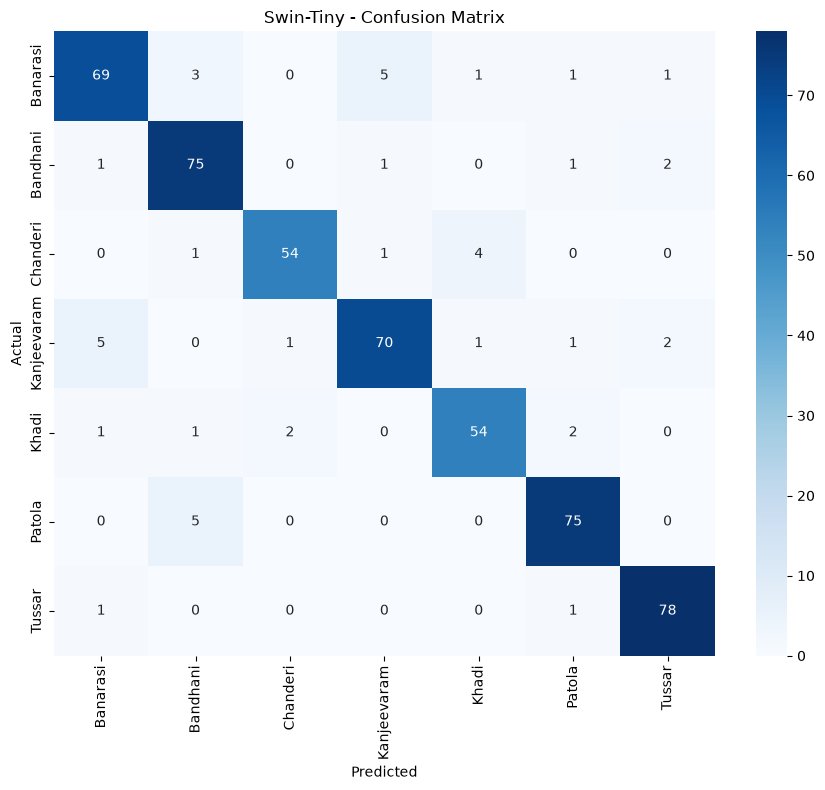

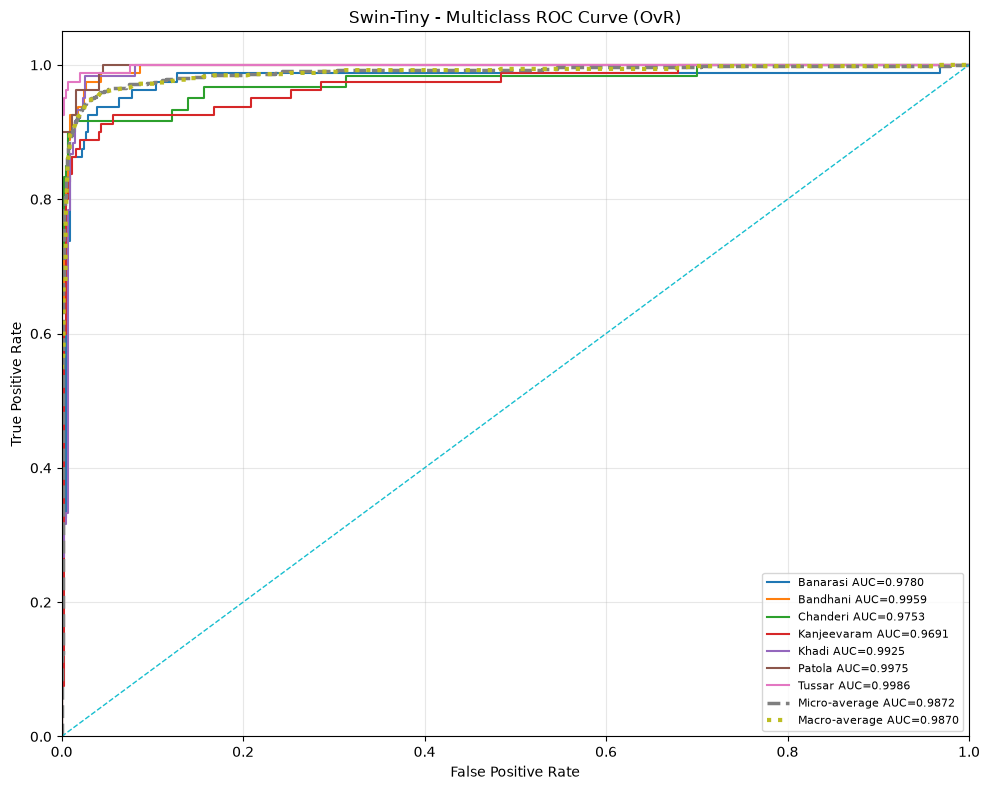


Swin-Tiny ROC-AUC:
Banarasi: 0.9780
Bandhani: 0.9959
Chanderi: 0.9753
Kanjeevaram: 0.9691
Khadi: 0.9925
Patola: 0.9975
Tussar: 0.9986
Macro AUC: 0.9870
Micro AUC: 0.9872
Weighted AUC: 0.9869


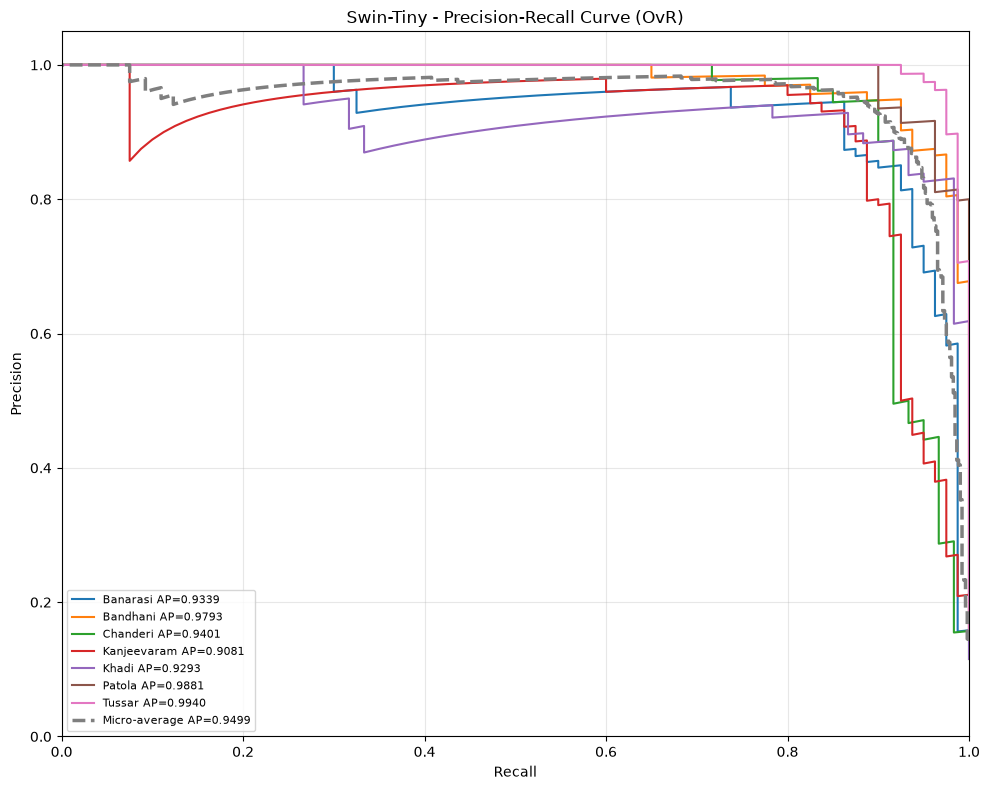


Swin-Tiny Average Precision:
Banarasi: 0.9339
Bandhani: 0.9793
Chanderi: 0.9401
Kanjeevaram: 0.9081
Khadi: 0.9293
Patola: 0.9881
Tussar: 0.9940
Macro AP: 0.9533
Micro AP: 0.9499
Weighted AP: 0.9547

Swin-Tiny Feature Shape: (520, 10)


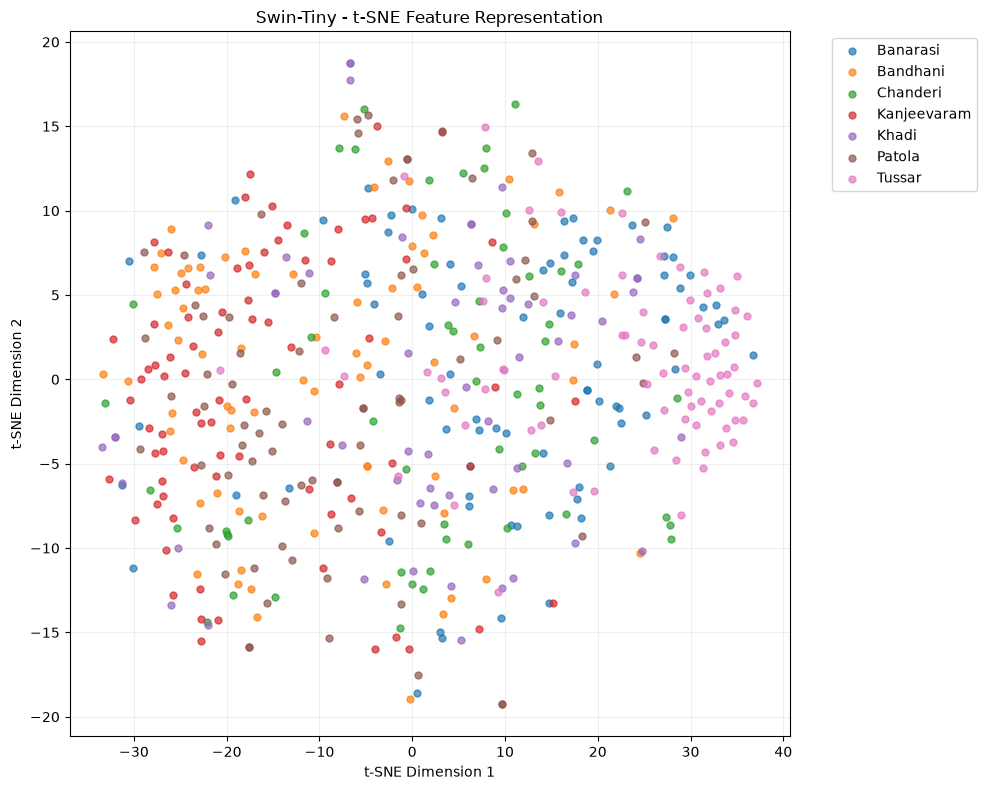

In [29]:
swin_results=evaluate_model(
    swin_tiny_ema,
    "Swin-Tiny"
)

# HybridWeaveNet

In [30]:
import torch
import torch.nn as nn
import timm

# ChannelAttention, SpatialAttention, DualAttention, and attach_attention()
# are already defined earlier in the notebook (right after the config cell)
# and are reused here for HybridWeaveNet's built-in attention.


In [31]:
class HybridWeaveNet(nn.Module):

    def __init__(
        self,
        num_classes=7,
        pretrained=True
    ):
        super().__init__()

        self.backbone = timm.create_model(
            "efficientnetv2_rw_s",
            pretrained=pretrained,
            num_classes=0,
            global_pool=""
        )

        channels = self.backbone.num_features

        print(
            "EfficientNetV2-RW-S feature channels:",
            channels
        )

        self.dual_attention = DualAttention(
            channels=channels,
            reduction=16,
            spatial_kernel=7
        )

        self.gap = nn.AdaptiveAvgPool2d(1)

        self.classifier = nn.Sequential(
            nn.Linear(
                channels,
                1024
            ),
            nn.GELU(),
            nn.Dropout(0.4),
            nn.Linear(
                1024,
                512
            ),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(
                512,
                num_classes
            )
        )

    def forward(self, x):

        x = self.backbone.forward_features(x)

        x = self.dual_attention(x)

        x = self.gap(x)

        x = torch.flatten(
            x,
            start_dim=1
        )

        x = self.classifier(x)

        return x


hybrid_weavenet = HybridWeaveNet(
    num_classes=num_classes,
    pretrained=True
)

hybrid_weavenet = hybrid_weavenet.to(DEVICE)

EfficientNetV2-RW-S feature channels: 1792


In [32]:
hybrid_weavenet,hybrid_weavenet_ema,hybrid_train_loss,hybrid_val_loss,hybrid_val_acc=train_model(hybrid_weavenet,"HybridWeaveNet")

HybridWeaveNet | Epoch 01/50 | Train Loss: 1.1461 | Train Acc: 0.3436 | Val Loss: 1.3877 | Val Acc: 0.2119
HybridWeaveNet | Epoch 02/50 | Train Loss: 0.7574 | Train Acc: 0.5819 | Val Loss: 1.3545 | Val Acc: 0.4181
HybridWeaveNet | Epoch 03/50 | Train Loss: 0.5692 | Train Acc: 0.6994 | Val Loss: 1.2742 | Val Acc: 0.6185
HybridWeaveNet | Epoch 04/50 | Train Loss: 0.5211 | Train Acc: 0.7347 | Val Loss: 1.1435 | Val Acc: 0.7206
HybridWeaveNet | Epoch 05/50 | Train Loss: 0.4680 | Train Acc: 0.7309 | Val Loss: 0.9720 | Val Acc: 0.7881
HybridWeaveNet | Epoch 06/50 | Train Loss: 0.4627 | Train Acc: 0.7765 | Val Loss: 0.7922 | Val Acc: 0.8304
HybridWeaveNet | Epoch 07/50 | Train Loss: 0.3938 | Train Acc: 0.8060 | Val Loss: 0.6295 | Val Acc: 0.8516
HybridWeaveNet | Epoch 08/50 | Train Loss: 0.3818 | Train Acc: 0.7836 | Val Loss: 0.5022 | Val Acc: 0.8651
HybridWeaveNet | Epoch 09/50 | Train Loss: 0.4219 | Train Acc: 0.7482 | Val Loss: 0.4183 | Val Acc: 0.8748
HybridWeaveNet | Epoch 10/50 | Train 


HybridWeaveNet Classification Report:
              precision    recall  f1-score   support

    Banarasi     0.8354    0.8250    0.8302        80
    Bandhani     0.8916    0.9250    0.9080        80
    Chanderi     0.8983    0.8833    0.8908        60
 Kanjeevaram     0.8625    0.8625    0.8625        80
       Khadi     0.8710    0.9000    0.8852        60
      Patola     0.9459    0.8750    0.9091        80
      Tussar     0.9398    0.9750    0.9571        80

    accuracy                         0.8923       520
   macro avg     0.8921    0.8923    0.8918       520
weighted avg     0.8926    0.8923    0.8921       520

HybridWeaveNet Accuracy  : 0.8923
HybridWeaveNet Precision : 0.8926
HybridWeaveNet Recall    : 0.8923
HybridWeaveNet F1-Score  : 0.8921


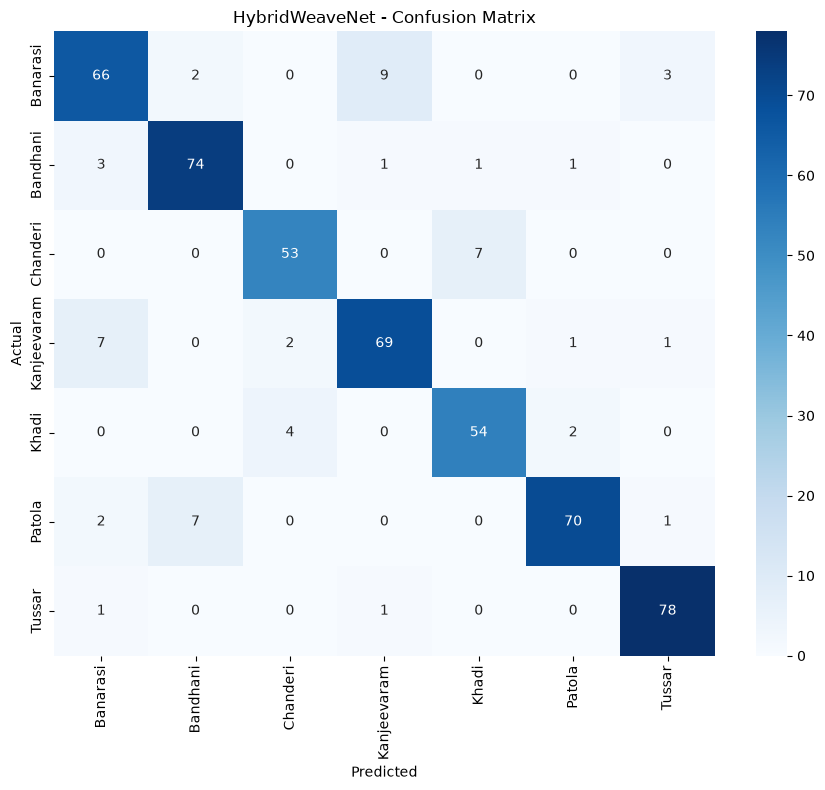

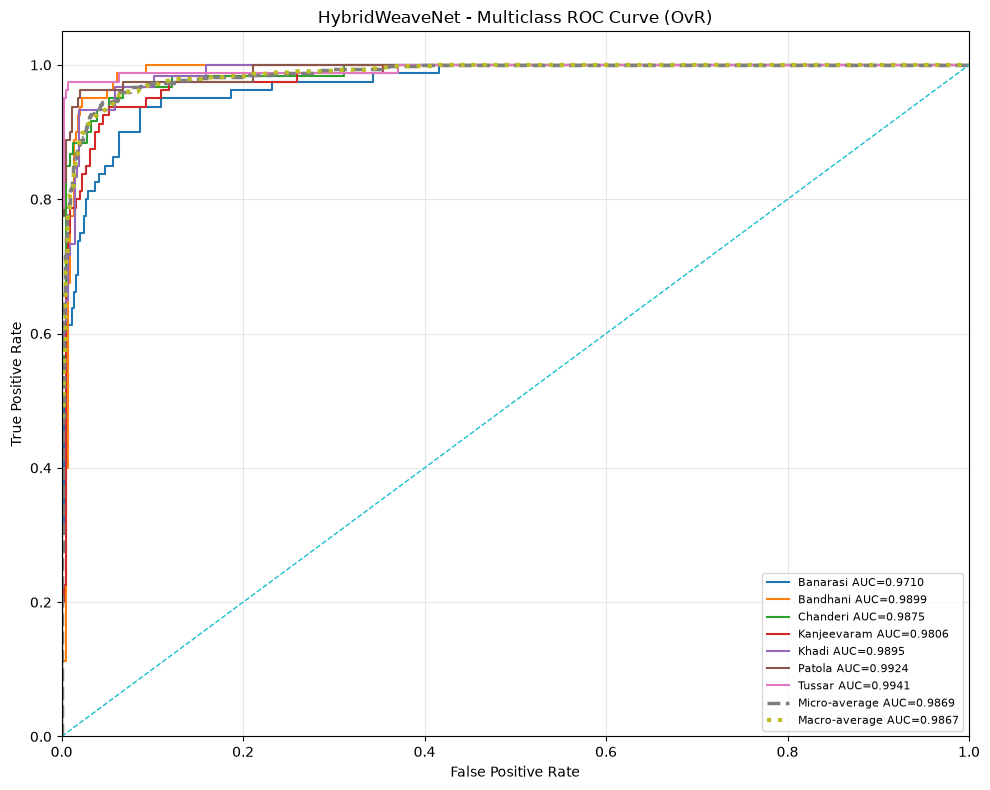


HybridWeaveNet ROC-AUC:
Banarasi: 0.9710
Bandhani: 0.9899
Chanderi: 0.9875
Kanjeevaram: 0.9806
Khadi: 0.9895
Patola: 0.9924
Tussar: 0.9941
Macro AUC: 0.9867
Micro AUC: 0.9869
Weighted AUC: 0.9863


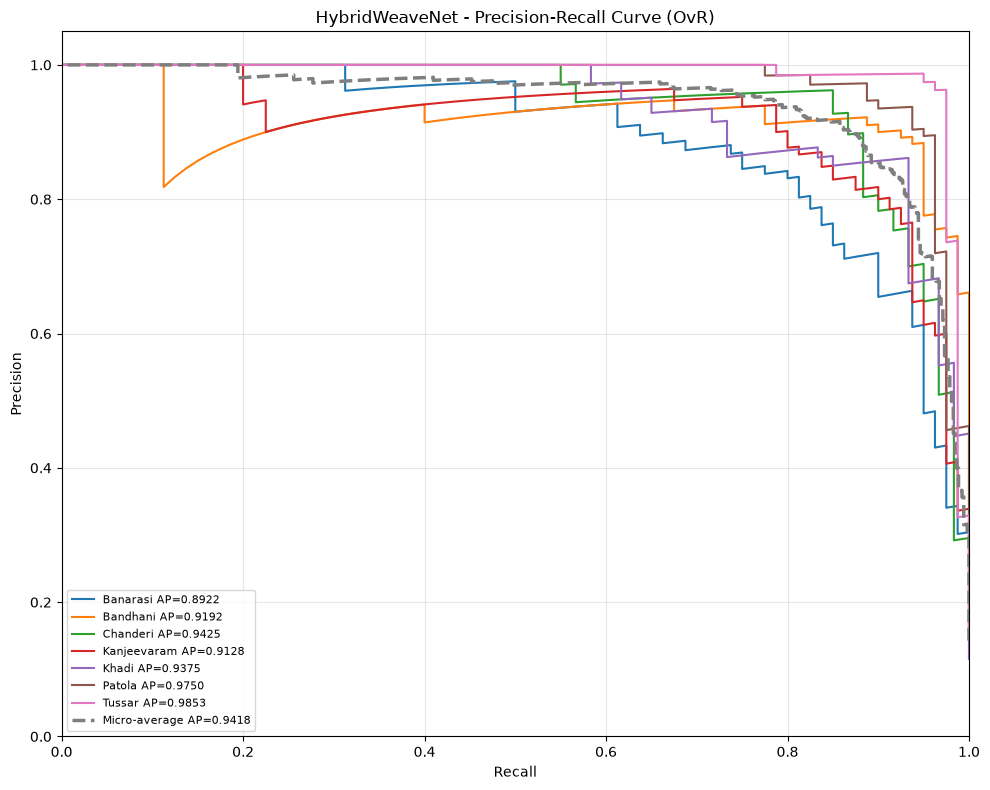


HybridWeaveNet Average Precision:
Banarasi: 0.8922
Bandhani: 0.9192
Chanderi: 0.9425
Kanjeevaram: 0.9128
Khadi: 0.9375
Patola: 0.9750
Tussar: 0.9853
Macro AP: 0.9378
Micro AP: 0.9418
Weighted AP: 0.9376

HybridWeaveNet Feature Shape: (520, 1792)


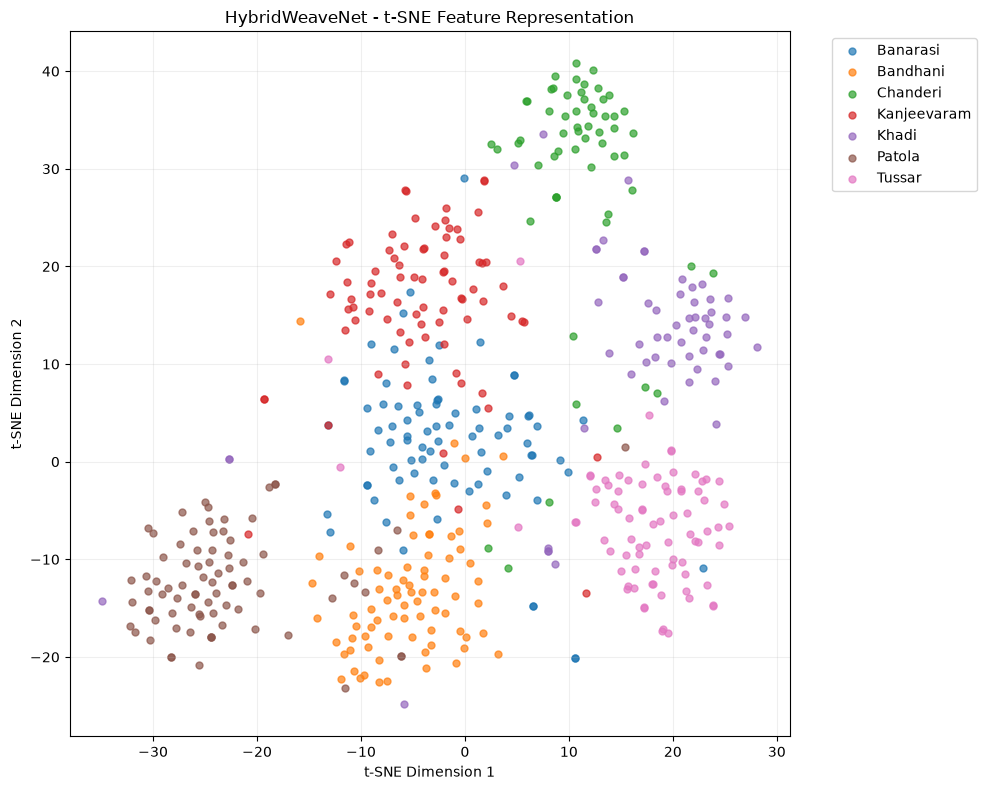

In [33]:
hybrid_results=evaluate_model(
    hybrid_weavenet_ema,
    "HybridWeaveNet"
)

# Xception (ATTENTION)

In [34]:
xception=timm.create_model(
    "xception",
    pretrained=True,
    num_classes=num_classes
)

xception=attach_attention(xception,xception.act4,channels=2048)
print("Attention added after Xception final feature block (2048 channels).")


f:\New folder\envs\gpuenv\Lib\site-packages\timm\models\_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Attention added after Xception final feature block (2048 channels).


In [35]:
xception,xception_ema,xception_train_loss,xception_val_loss,xception_val_acc=train_model(xception,"Xception")

Xception | Epoch 01/50 | Train Loss: 1.1463 | Train Acc: 0.3776 | Val Loss: 1.3449 | Val Acc: 0.3487
Xception | Epoch 02/50 | Train Loss: 0.6853 | Train Acc: 0.6448 | Val Loss: 1.2060 | Val Acc: 0.5279
Xception | Epoch 03/50 | Train Loss: 0.5673 | Train Acc: 0.6782 | Val Loss: 1.0176 | Val Acc: 0.6667
Xception | Epoch 04/50 | Train Loss: 0.5634 | Train Acc: 0.7206 | Val Loss: 0.8267 | Val Acc: 0.7341
Xception | Epoch 05/50 | Train Loss: 0.4806 | Train Acc: 0.7746 | Val Loss: 0.6506 | Val Acc: 0.7803
Xception | Epoch 06/50 | Train Loss: 0.4528 | Train Acc: 0.7829 | Val Loss: 0.5190 | Val Acc: 0.8189
Xception | Epoch 07/50 | Train Loss: 0.4227 | Train Acc: 0.7874 | Val Loss: 0.4299 | Val Acc: 0.8459
Xception | Epoch 08/50 | Train Loss: 0.3912 | Train Acc: 0.7842 | Val Loss: 0.3750 | Val Acc: 0.8651
Xception | Epoch 09/50 | Train Loss: 0.3821 | Train Acc: 0.8240 | Val Loss: 0.3424 | Val Acc: 0.8690
Xception | Epoch 10/50 | Train Loss: 0.3630 | Train Acc: 0.7945 | Val Loss: 0.3219 | Val Ac


Xception Classification Report:
              precision    recall  f1-score   support

    Banarasi     0.8289    0.7875    0.8077        80
    Bandhani     0.8795    0.9125    0.8957        80
    Chanderi     0.8254    0.8667    0.8455        60
 Kanjeevaram     0.8378    0.7750    0.8052        80
       Khadi     0.8548    0.8833    0.8689        60
      Patola     0.9481    0.9125    0.9299        80
      Tussar     0.9059    0.9625    0.9333        80

    accuracy                         0.8712       520
   macro avg     0.8686    0.8714    0.8695       520
weighted avg     0.8708    0.8712    0.8704       520

Xception Accuracy  : 0.8712
Xception Precision : 0.8708
Xception Recall    : 0.8712
Xception F1-Score  : 0.8704


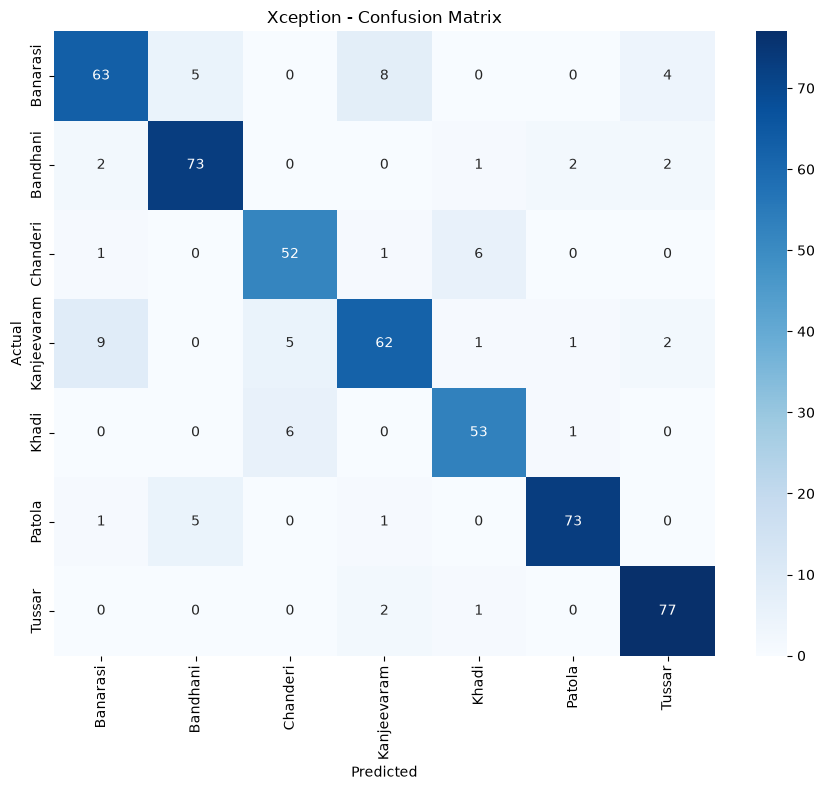

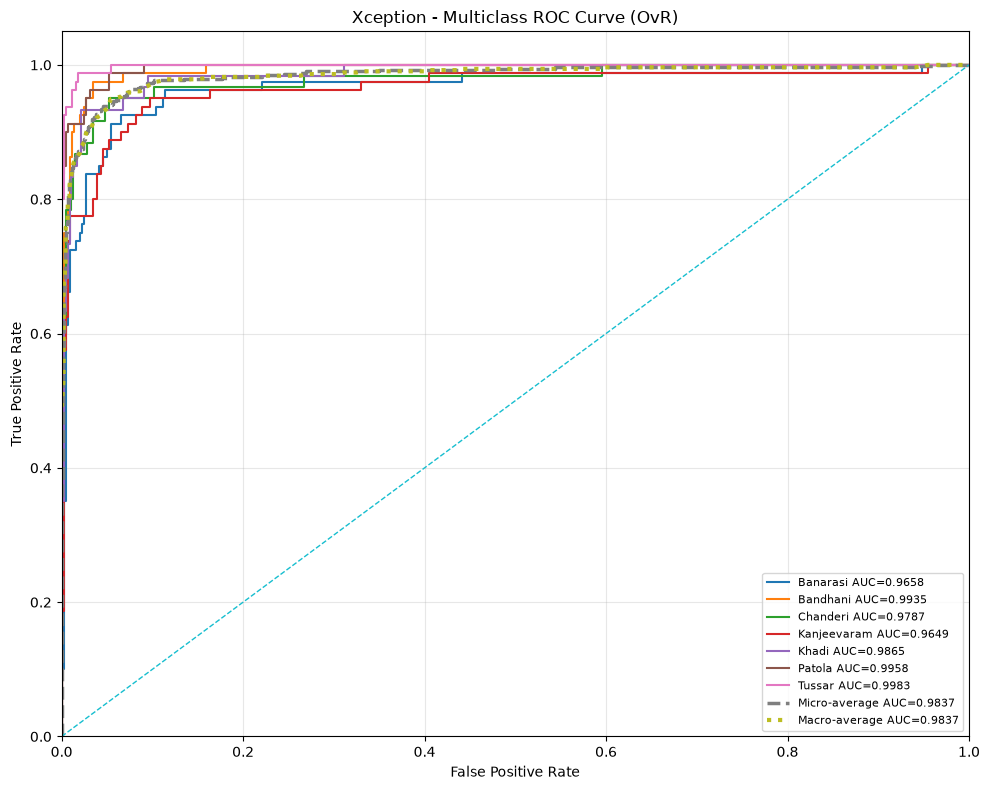


Xception ROC-AUC:
Banarasi: 0.9658
Bandhani: 0.9935
Chanderi: 0.9787
Kanjeevaram: 0.9649
Khadi: 0.9865
Patola: 0.9958
Tussar: 0.9983
Macro AUC: 0.9837
Micro AUC: 0.9837
Weighted AUC: 0.9834


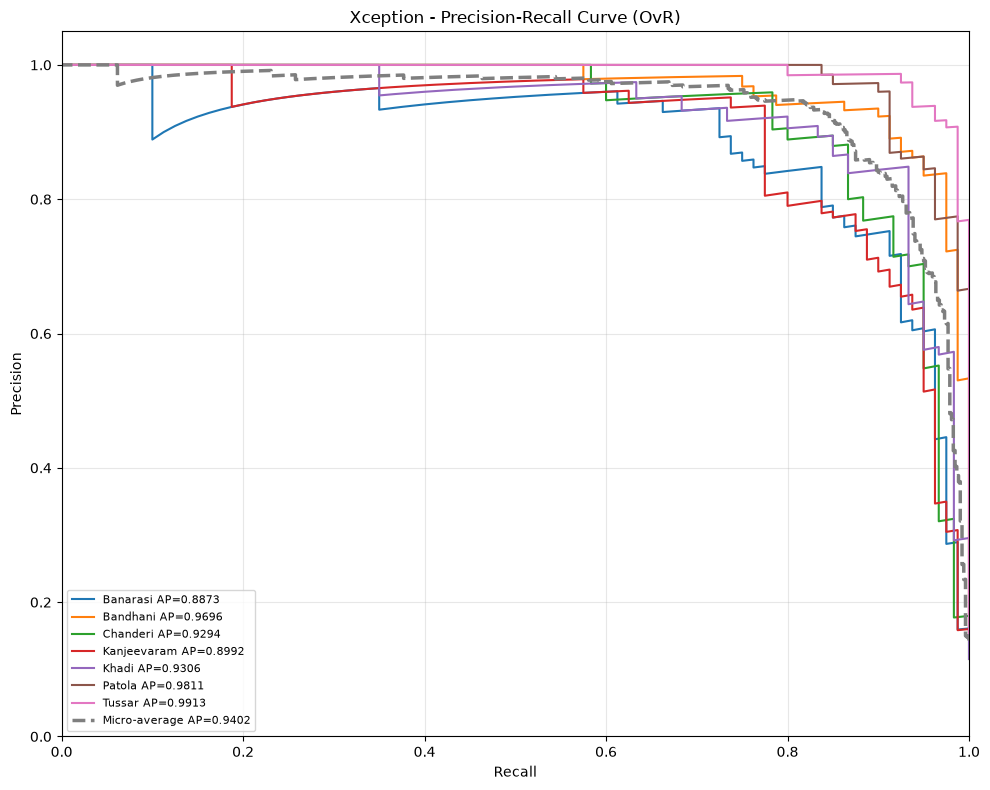


Xception Average Precision:
Banarasi: 0.8873
Bandhani: 0.9696
Chanderi: 0.9294
Kanjeevaram: 0.8992
Khadi: 0.9306
Patola: 0.9811
Tussar: 0.9913
Macro AP: 0.9412
Micro AP: 0.9402
Weighted AP: 0.9421

Xception Feature Shape: (520, 2048)


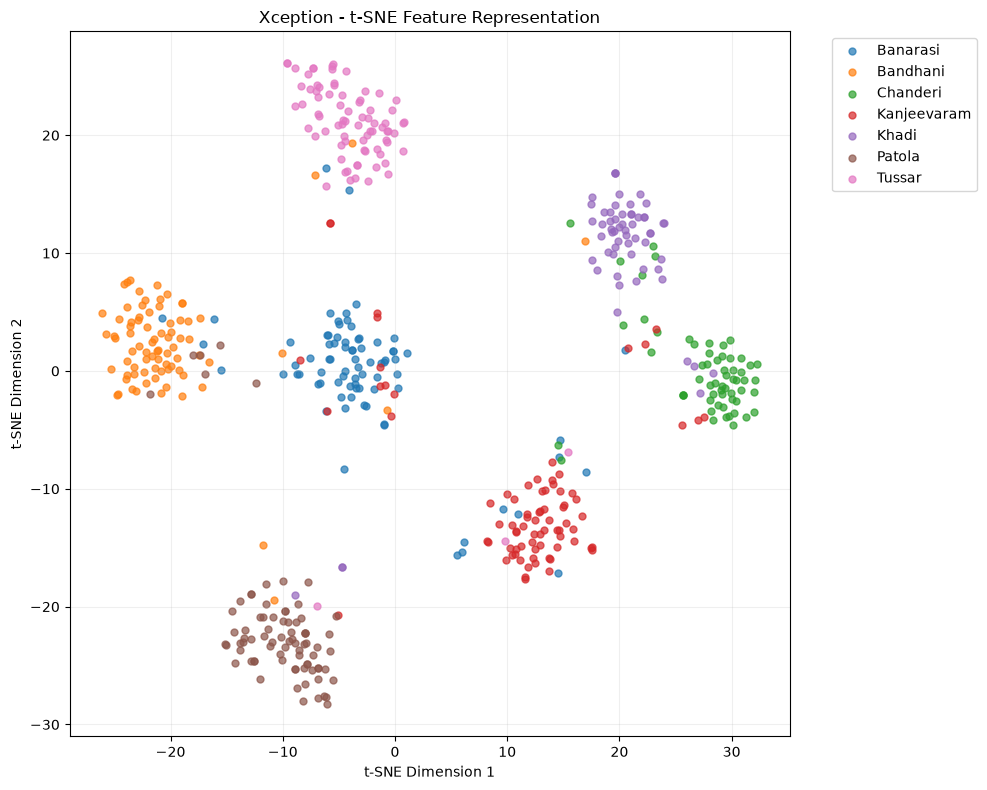

In [36]:
xception_results=evaluate_model(
    xception_ema,
    "Xception"
)

# ConvNeXt-Base 

In [37]:
convnext_base=timm.create_model("convnext_base",pretrained=True,num_classes=num_classes,drop_path_rate=0.3)

In [38]:
_LR_BACKUP,_PATIENCE_BACKUP=LEARNING_RATE,PATIENCE
LEARNING_RATE=3e-5
PATIENCE=7

convnext_base,convnext_base_ema,convnext_base_train_loss,convnext_base_val_loss,convnext_base_val_acc=train_model(convnext_base,"ConvNeXt-Base")

LEARNING_RATE,PATIENCE=_LR_BACKUP,_PATIENCE_BACKUP

ConvNeXt-Base | Epoch 01/50 | Train Loss: 0.8689 | Train Acc: 0.5112 | Val Loss: 1.2322 | Val Acc: 0.3237
ConvNeXt-Base | Epoch 02/50 | Train Loss: 0.5444 | Train Acc: 0.6885 | Val Loss: 0.9610 | Val Acc: 0.5010
ConvNeXt-Base | Epoch 03/50 | Train Loss: 0.4083 | Train Acc: 0.7887 | Val Loss: 0.7303 | Val Acc: 0.6782
ConvNeXt-Base | Epoch 04/50 | Train Loss: 0.3645 | Train Acc: 0.7951 | Val Loss: 0.5573 | Val Acc: 0.7611
ConvNeXt-Base | Epoch 05/50 | Train Loss: 0.3780 | Train Acc: 0.7977 | Val Loss: 0.4408 | Val Acc: 0.8285
ConvNeXt-Base | Epoch 06/50 | Train Loss: 0.3456 | Train Acc: 0.8022 | Val Loss: 0.3635 | Val Acc: 0.8497
ConvNeXt-Base | Epoch 07/50 | Train Loss: 0.3264 | Train Acc: 0.8189 | Val Loss: 0.3156 | Val Acc: 0.8748
ConvNeXt-Base | Epoch 08/50 | Train Loss: 0.3028 | Train Acc: 0.8401 | Val Loss: 0.2848 | Val Acc: 0.8786
ConvNeXt-Base | Epoch 09/50 | Train Loss: 0.3093 | Train Acc: 0.8144 | Val Loss: 0.2648 | Val Acc: 0.8825
ConvNeXt-Base | Epoch 10/50 | Train Loss: 0.28


ConvNeXt-Base Classification Report:
              precision    recall  f1-score   support

    Banarasi     0.8875    0.8875    0.8875        80
    Bandhani     0.9176    0.9750    0.9455        80
    Chanderi     0.8667    0.8667    0.8667        60
 Kanjeevaram     0.9315    0.8500    0.8889        80
       Khadi     0.8710    0.9000    0.8852        60
      Patola     0.9367    0.9250    0.9308        80
      Tussar     0.9630    0.9750    0.9689        80

    accuracy                         0.9135       520
   macro avg     0.9106    0.9113    0.9105       520
weighted avg     0.9138    0.9135    0.9132       520

ConvNeXt-Base Accuracy  : 0.9135
ConvNeXt-Base Precision : 0.9138
ConvNeXt-Base Recall    : 0.9135
ConvNeXt-Base F1-Score  : 0.9132


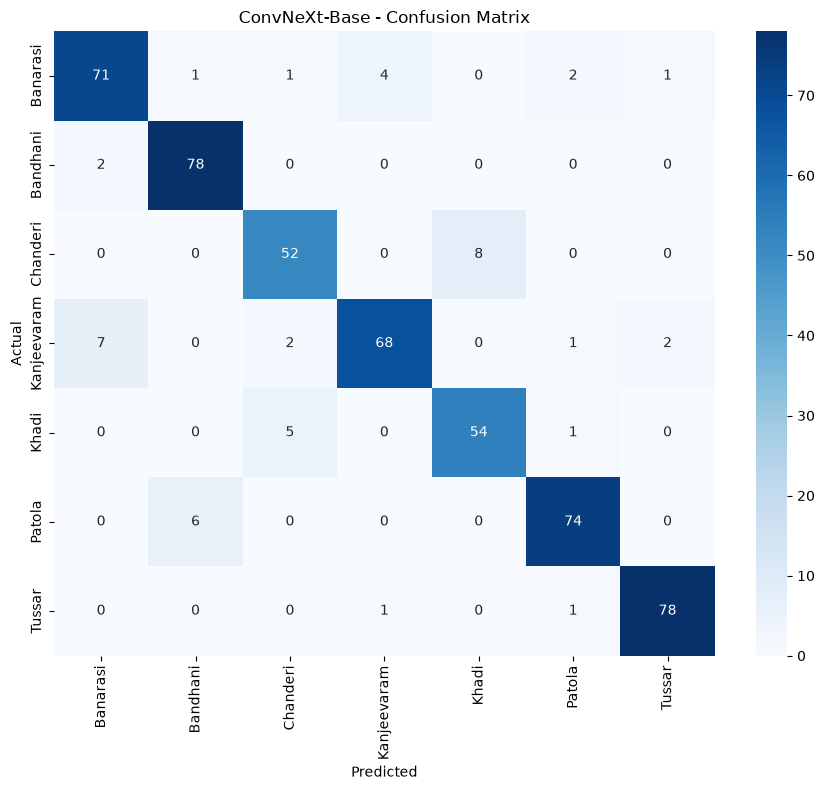

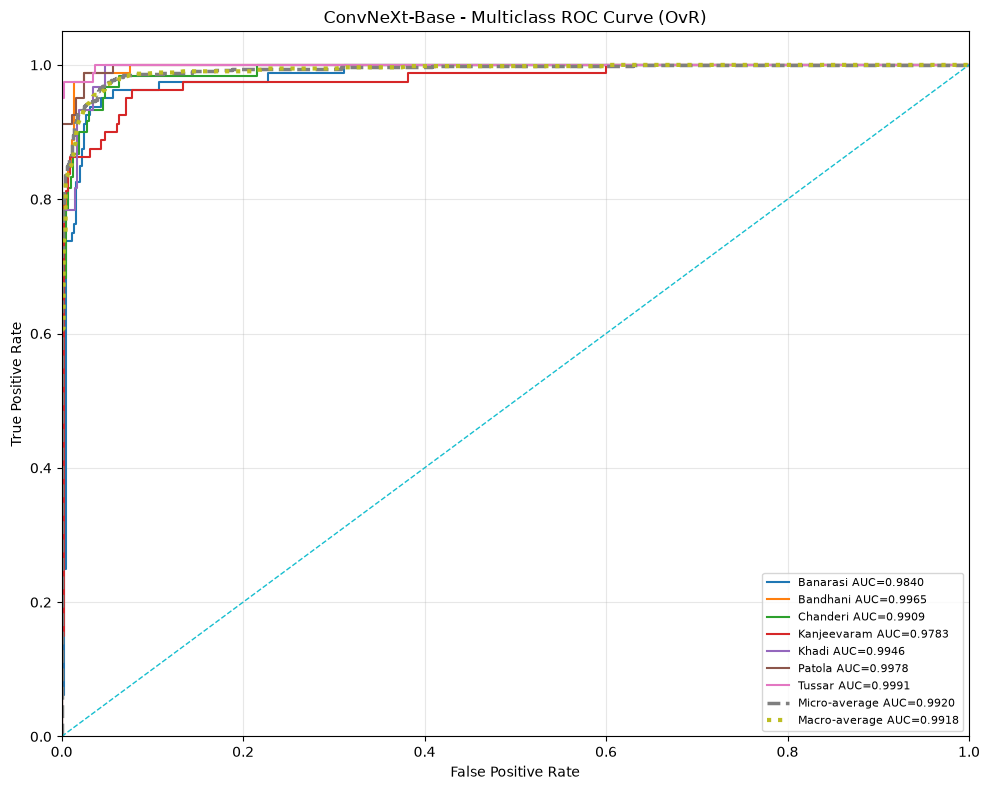


ConvNeXt-Base ROC-AUC:
Banarasi: 0.9840
Bandhani: 0.9965
Chanderi: 0.9909
Kanjeevaram: 0.9783
Khadi: 0.9946
Patola: 0.9978
Tussar: 0.9991
Macro AUC: 0.9918
Micro AUC: 0.9920
Weighted AUC: 0.9915


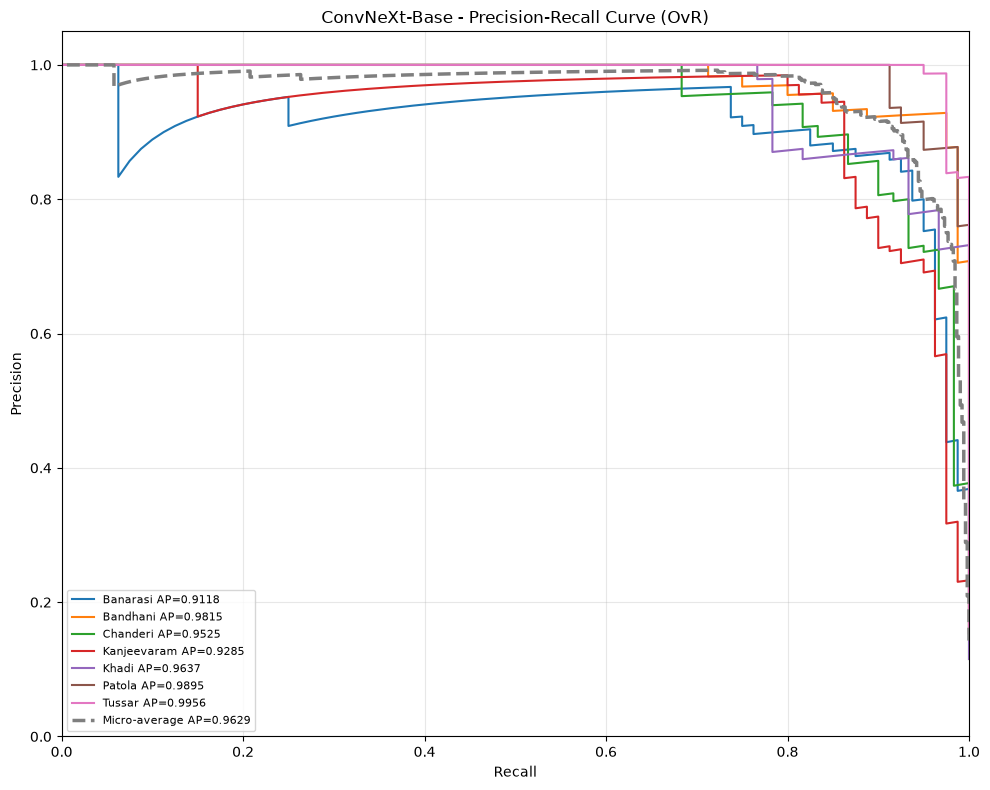


ConvNeXt-Base Average Precision:
Banarasi: 0.9118
Bandhani: 0.9815
Chanderi: 0.9525
Kanjeevaram: 0.9285
Khadi: 0.9637
Patola: 0.9895
Tussar: 0.9956
Macro AP: 0.9604
Micro AP: 0.9629
Weighted AP: 0.9606

ConvNeXt-Base Feature Shape: (520, 1024)


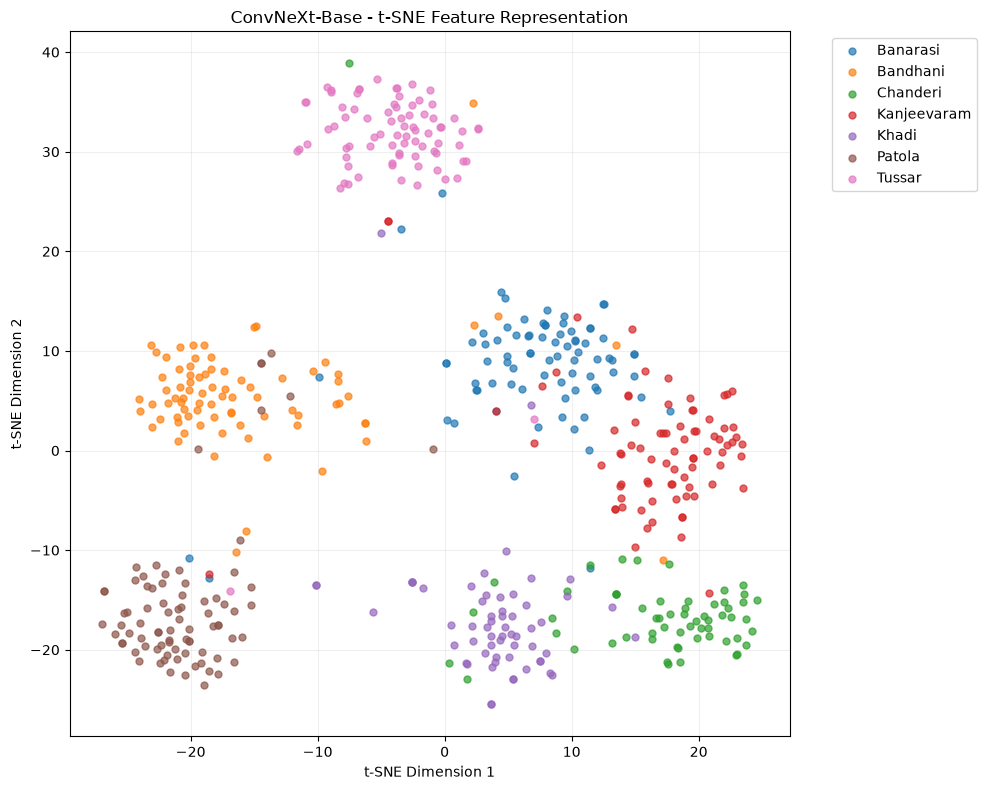

In [39]:
convnext_base_results=evaluate_model(
    convnext_base_ema,
    "ConvNeXt-Base"
)

# CONVNEXT AT STAGE-3

In [40]:
from timm.models.convnext import ConvNeXtBlock
import torch.nn as nn

convnext_base_stage3deeper = timm.create_model("convnext_base", pretrained=True, num_classes=num_classes, drop_path_rate=0.3)

stage3_channels = 512      # ConvNeXt-Base's stage 3 (index 2) channel width
extra_blocks = 5           # how many NEW blocks to add to stage 3 — change this number as you like

stage3 = convnext_base_stage3deeper.stages[2]   # index 2 = 3rd stage (0-indexed)
current_blocks = list(stage3.blocks)
print("Stage 3 block count BEFORE:", len(current_blocks))

new_blocks = [ConvNeXtBlock(in_chs=stage3_channels, out_chs=stage3_channels) for _ in range(extra_blocks)]
stage3.blocks = nn.Sequential(*(current_blocks + new_blocks))

print("Stage 3 block count AFTER:", len(stage3.blocks))
print("Stages 1, 2, 4 block counts (should be UNCHANGED — 3, 3, 3):",
      len(convnext_base_stage3deeper.stages[0].blocks),
      len(convnext_base_stage3deeper.stages[1].blocks),
      len(convnext_base_stage3deeper.stages[3].blocks))

Stage 3 block count BEFORE: 27
Stage 3 block count AFTER: 32
Stages 1, 2, 4 block counts (should be UNCHANGED — 3, 3, 3): 3 3 3


In [41]:
_LR_BACKUP,_PATIENCE_BACKUP=LEARNING_RATE,PATIENCE
LEARNING_RATE=3e-5
PATIENCE=7

convnext_base_stage3deeper,convnext_base_stage3deeper_ema,convnext_base_stage3deeper_train_loss,convnext_base_stage3deeper_val_loss,convnext_base_stage3deeper_val_acc=train_model(convnext_base_stage3deeper,"ConvNeXt-Base (Stage3 Deeper)")

LEARNING_RATE,PATIENCE=_LR_BACKUP,_PATIENCE_BACKUP

ConvNeXt-Base (Stage3 Deeper) | Epoch 01/50 | Train Loss: 0.9412 | Train Acc: 0.4708 | Val Loss: 1.3163 | Val Acc: 0.2890
ConvNeXt-Base (Stage3 Deeper) | Epoch 02/50 | Train Loss: 0.5933 | Train Acc: 0.6448 | Val Loss: 1.0181 | Val Acc: 0.4721
ConvNeXt-Base (Stage3 Deeper) | Epoch 03/50 | Train Loss: 0.4939 | Train Acc: 0.7097 | Val Loss: 0.7599 | Val Acc: 0.6647
ConvNeXt-Base (Stage3 Deeper) | Epoch 04/50 | Train Loss: 0.4213 | Train Acc: 0.7791 | Val Loss: 0.5714 | Val Acc: 0.7630
ConvNeXt-Base (Stage3 Deeper) | Epoch 05/50 | Train Loss: 0.3921 | Train Acc: 0.8112 | Val Loss: 0.4484 | Val Acc: 0.7881
ConvNeXt-Base (Stage3 Deeper) | Epoch 06/50 | Train Loss: 0.3334 | Train Acc: 0.8125 | Val Loss: 0.3648 | Val Acc: 0.8285
ConvNeXt-Base (Stage3 Deeper) | Epoch 07/50 | Train Loss: 0.3315 | Train Acc: 0.8080 | Val Loss: 0.3154 | Val Acc: 0.8497
ConvNeXt-Base (Stage3 Deeper) | Epoch 08/50 | Train Loss: 0.2902 | Train Acc: 0.8253 | Val Loss: 0.2827 | Val Acc: 0.8671
ConvNeXt-Base (Stage3 De


ConvNeXt-Base (Stage3 Deeper) Classification Report:
              precision    recall  f1-score   support

    Banarasi     0.8554    0.8875    0.8712        80
    Bandhani     0.9259    0.9375    0.9317        80
    Chanderi     0.8966    0.8667    0.8814        60
 Kanjeevaram     0.9577    0.8500    0.9007        80
       Khadi     0.8906    0.9500    0.9194        60
      Patola     0.9375    0.9375    0.9375        80
      Tussar     0.9398    0.9750    0.9571        80

    accuracy                         0.9154       520
   macro avg     0.9148    0.9149    0.9141       520
weighted avg     0.9164    0.9154    0.9152       520

ConvNeXt-Base (Stage3 Deeper) Accuracy  : 0.9154
ConvNeXt-Base (Stage3 Deeper) Precision : 0.9164
ConvNeXt-Base (Stage3 Deeper) Recall    : 0.9154
ConvNeXt-Base (Stage3 Deeper) F1-Score  : 0.9152


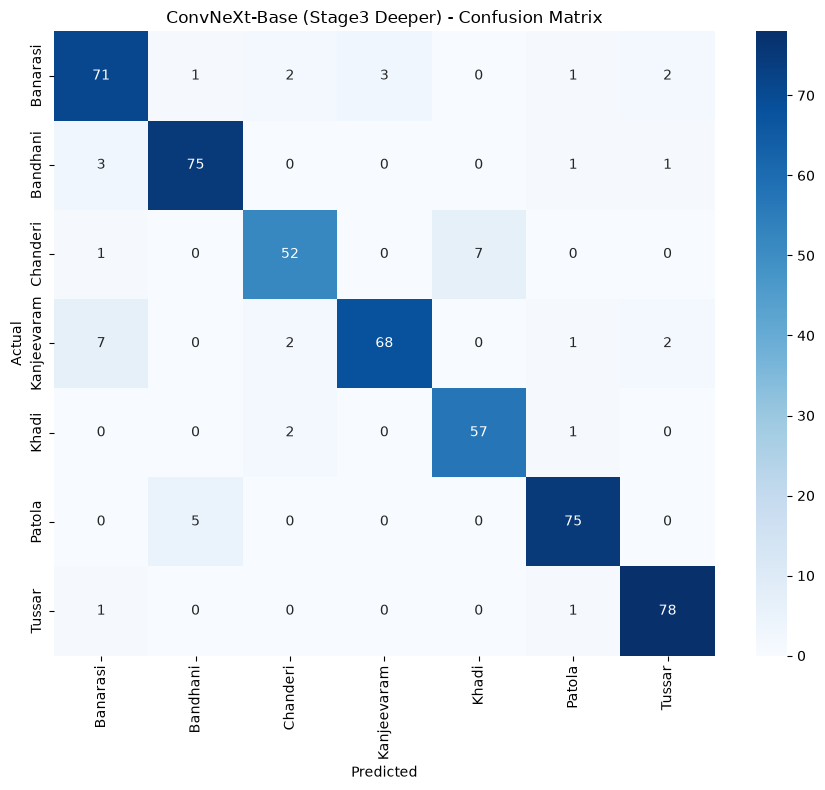

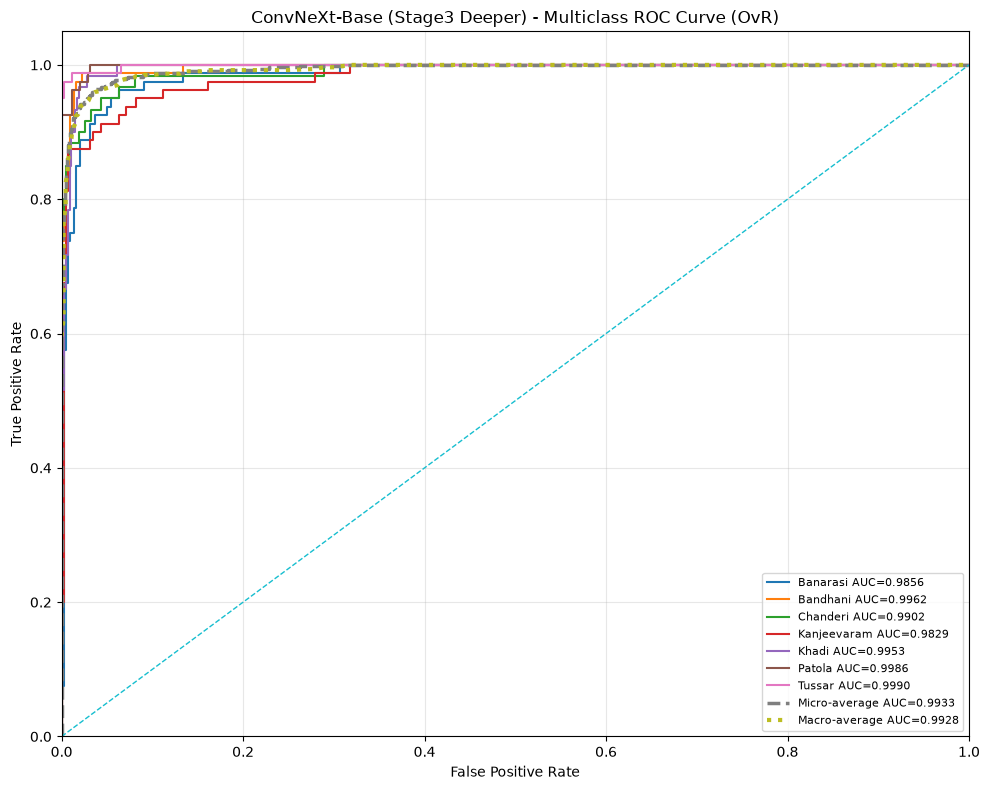


ConvNeXt-Base (Stage3 Deeper) ROC-AUC:
Banarasi: 0.9856
Bandhani: 0.9962
Chanderi: 0.9902
Kanjeevaram: 0.9829
Khadi: 0.9953
Patola: 0.9986
Tussar: 0.9990
Macro AUC: 0.9928
Micro AUC: 0.9933
Weighted AUC: 0.9925


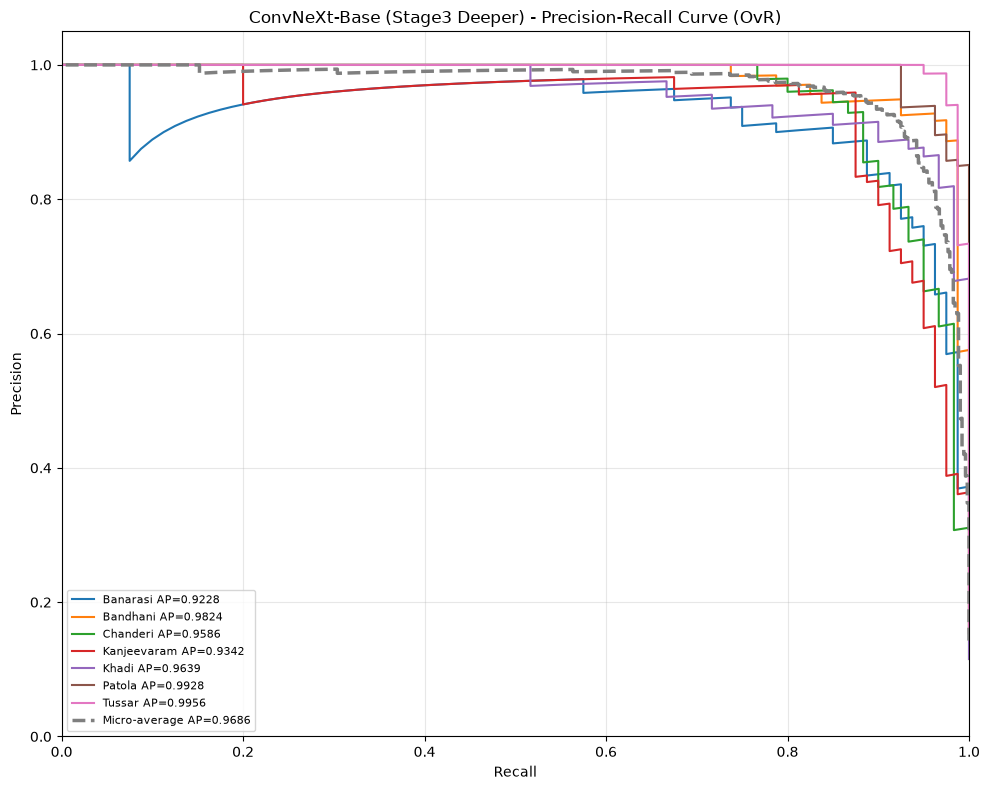


ConvNeXt-Base (Stage3 Deeper) Average Precision:
Banarasi: 0.9228
Bandhani: 0.9824
Chanderi: 0.9586
Kanjeevaram: 0.9342
Khadi: 0.9639
Patola: 0.9928
Tussar: 0.9956
Macro AP: 0.9643
Micro AP: 0.9686
Weighted AP: 0.9646

ConvNeXt-Base (Stage3 Deeper) Feature Shape: (520, 1024)


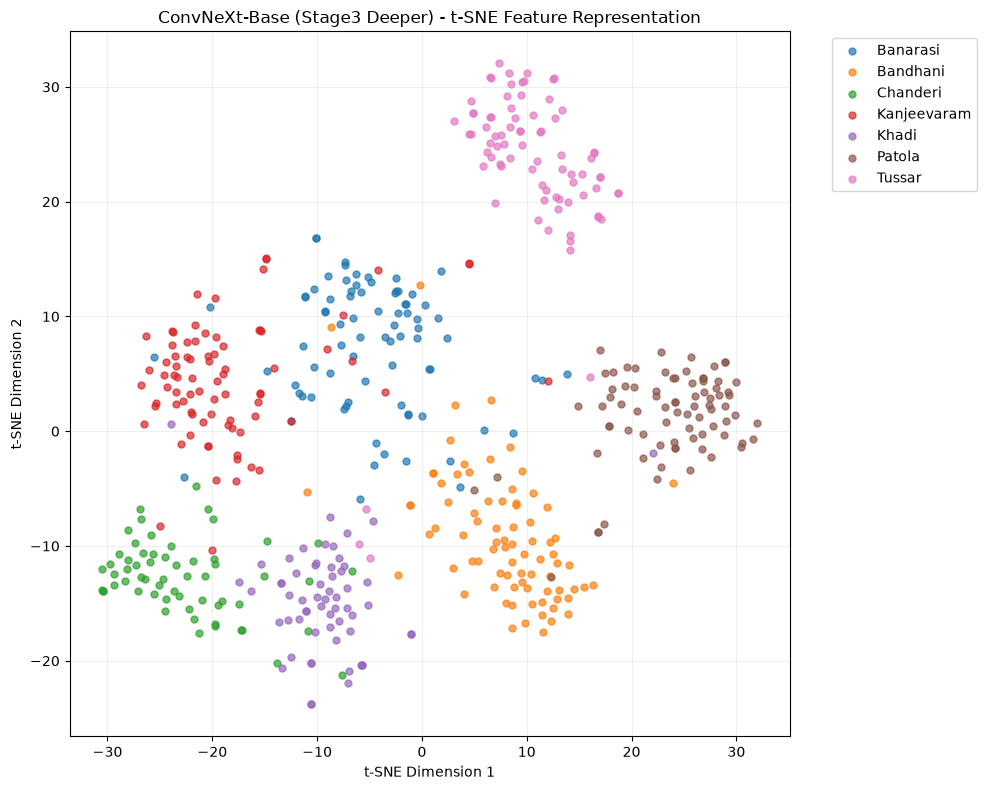

In [42]:
convnext_base_stage3deeper_results=evaluate_model(
    convnext_base_stage3deeper_ema,
    "ConvNeXt-Base (Stage3 Deeper)"
)

# conv-base at each block 

In [43]:
from timm.models.convnext import ConvNeXtBlock
import torch.nn as nn

convnext_base_deeper = timm.create_model("convnext_base", pretrained=True, num_classes=num_classes, drop_path_rate=0.3)

stage_channels = [128, 256, 512, 1024]
target_blocks = [4, 4, 30, 4]   # your chosen ratio

for stage, ch, target_n in zip(convnext_base_deeper.stages, stage_channels, target_blocks):
    current_blocks = list(stage.blocks)
    current_n = len(current_blocks)
    if target_n > current_n:
        new_blocks = [ConvNeXtBlock(in_chs=ch, out_chs=ch) for _ in range(target_n - current_n)]
        stage.blocks = nn.Sequential(*(current_blocks + new_blocks))
    elif target_n < current_n:
        stage.blocks = nn.Sequential(*current_blocks[:target_n])

print(convnext_base_deeper.stages[2])

ConvNeXtStage(
  (downsample): Sequential(
    (0): LayerNorm2d((256,), eps=1e-06, elementwise_affine=True)
    (1): Conv2d(256, 512, kernel_size=(2, 2), stride=(2, 2))
  )
  (blocks): Sequential(
    (0): ConvNeXtBlock(
      (conv_dw): Conv2d(512, 512, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=512)
      (norm): LayerNorm((512,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=512, out_features=2048, bias=True)
        (act): GELU()
        (drop1): Dropout(p=0.0, inplace=False)
        (norm): Identity()
        (fc2): Linear(in_features=2048, out_features=512, bias=True)
        (drop2): Dropout(p=0.0, inplace=False)
      )
      (shortcut): Identity()
      (drop_path): DropPath(drop_prob=0.051)
    )
    (1): ConvNeXtBlock(
      (conv_dw): Conv2d(512, 512, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=512)
      (norm): LayerNorm((512,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linea

In [44]:
_LR_BACKUP,_PATIENCE_BACKUP=LEARNING_RATE,PATIENCE
LEARNING_RATE=3e-5
PATIENCE=7

convnext_base_deeper,convnext_base_deeper_ema,convnext_base_deeper_train_loss,convnext_base_deeper_val_loss,convnext_base_deeper_val_acc=train_model(convnext_base_deeper,"ConvNeXt-Base (Deeper)")

LEARNING_RATE,PATIENCE=_LR_BACKUP,_PATIENCE_BACKUP

ConvNeXt-Base (Deeper) | Epoch 01/50 | Train Loss: 0.9719 | Train Acc: 0.4560 | Val Loss: 1.2505 | Val Acc: 0.2967
ConvNeXt-Base (Deeper) | Epoch 02/50 | Train Loss: 0.5853 | Train Acc: 0.6840 | Val Loss: 0.9603 | Val Acc: 0.5164
ConvNeXt-Base (Deeper) | Epoch 03/50 | Train Loss: 0.4322 | Train Acc: 0.7707 | Val Loss: 0.7116 | Val Acc: 0.7033
ConvNeXt-Base (Deeper) | Epoch 04/50 | Train Loss: 0.3875 | Train Acc: 0.8099 | Val Loss: 0.5354 | Val Acc: 0.7726
ConvNeXt-Base (Deeper) | Epoch 05/50 | Train Loss: 0.3742 | Train Acc: 0.8003 | Val Loss: 0.4174 | Val Acc: 0.8266
ConvNeXt-Base (Deeper) | Epoch 06/50 | Train Loss: 0.3586 | Train Acc: 0.7778 | Val Loss: 0.3418 | Val Acc: 0.8709
ConvNeXt-Base (Deeper) | Epoch 07/50 | Train Loss: 0.3078 | Train Acc: 0.8433 | Val Loss: 0.2977 | Val Acc: 0.8805
ConvNeXt-Base (Deeper) | Epoch 08/50 | Train Loss: 0.2938 | Train Acc: 0.8099 | Val Loss: 0.2709 | Val Acc: 0.8825
ConvNeXt-Base (Deeper) | Epoch 09/50 | Train Loss: 0.2733 | Train Acc: 0.8426 | 


ConvNeXt-Base (Deeper) Classification Report:
              precision    recall  f1-score   support

    Banarasi     0.9000    0.9000    0.9000        80
    Bandhani     0.9390    0.9625    0.9506        80
    Chanderi     0.8814    0.8667    0.8739        60
 Kanjeevaram     0.9452    0.8625    0.9020        80
       Khadi     0.8710    0.9000    0.8852        60
      Patola     0.9268    0.9500    0.9383        80
      Tussar     0.9512    0.9750    0.9630        80

    accuracy                         0.9192       520
   macro avg     0.9164    0.9167    0.9161       520
weighted avg     0.9195    0.9192    0.9190       520

ConvNeXt-Base (Deeper) Accuracy  : 0.9192
ConvNeXt-Base (Deeper) Precision : 0.9195
ConvNeXt-Base (Deeper) Recall    : 0.9192
ConvNeXt-Base (Deeper) F1-Score  : 0.9190


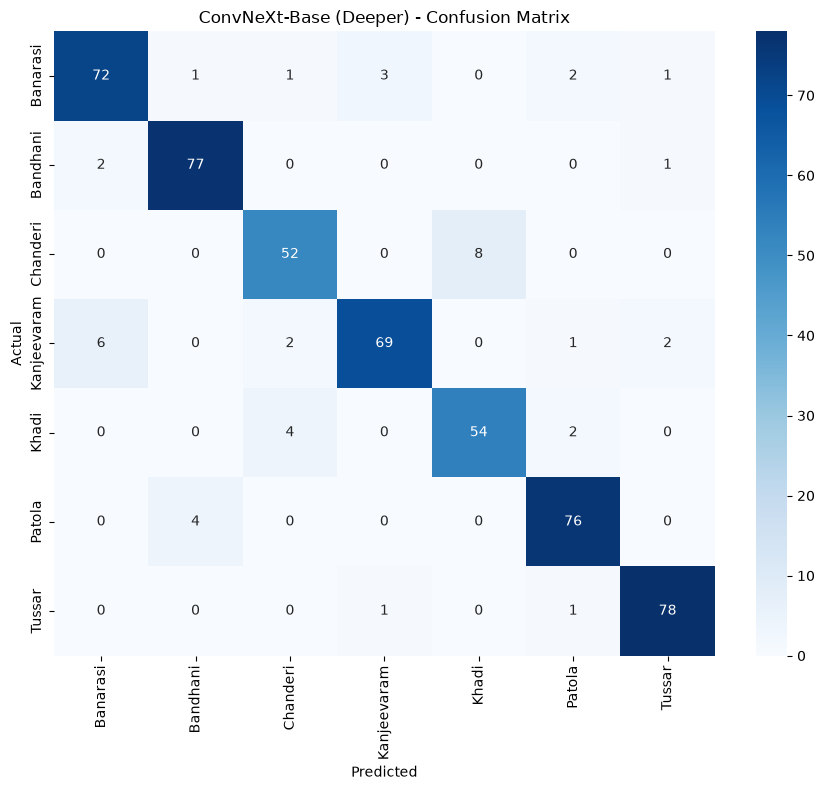

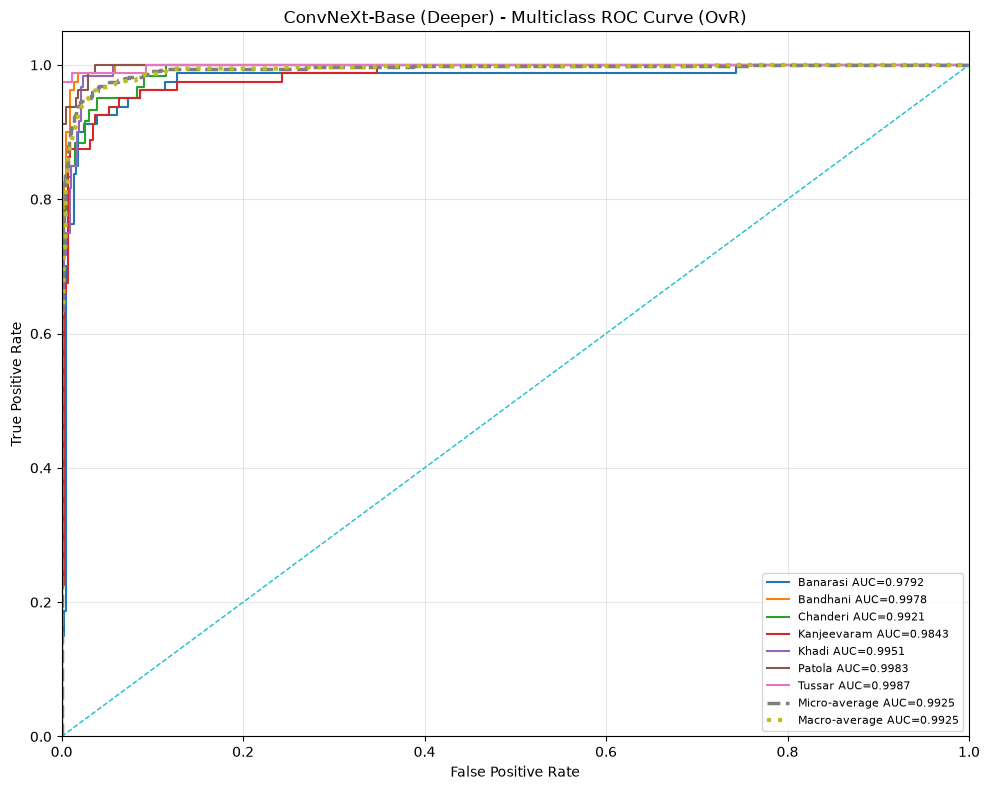


ConvNeXt-Base (Deeper) ROC-AUC:
Banarasi: 0.9792
Bandhani: 0.9978
Chanderi: 0.9921
Kanjeevaram: 0.9843
Khadi: 0.9951
Patola: 0.9983
Tussar: 0.9987
Macro AUC: 0.9925
Micro AUC: 0.9925
Weighted AUC: 0.9921


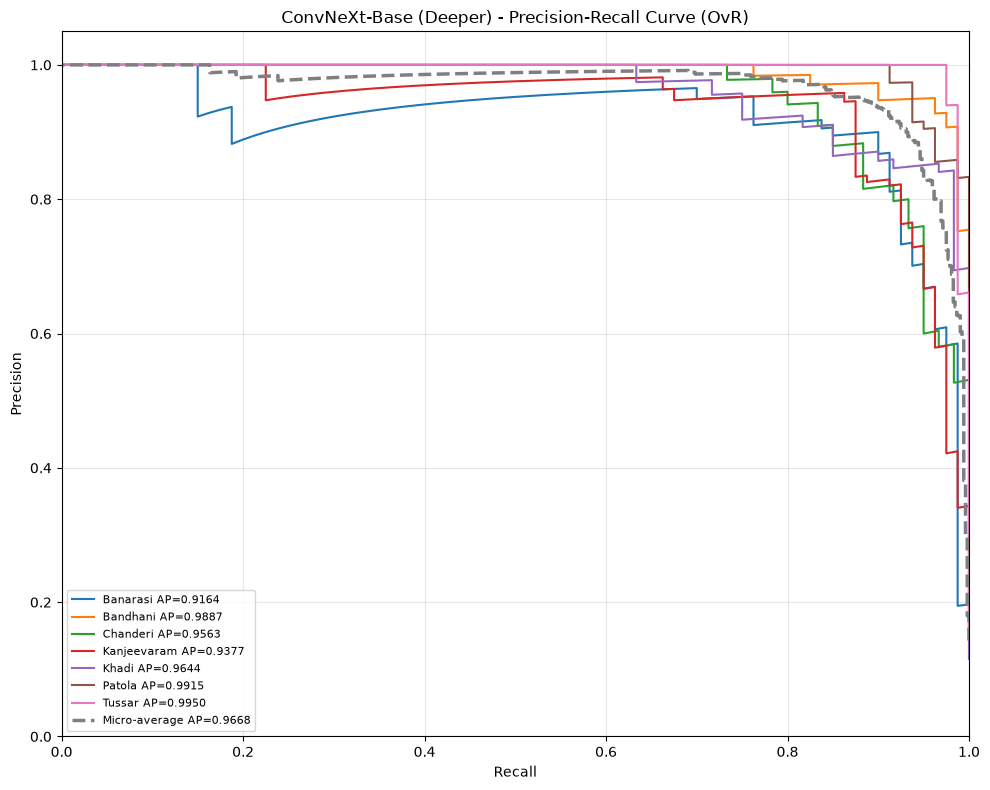


ConvNeXt-Base (Deeper) Average Precision:
Banarasi: 0.9164
Bandhani: 0.9887
Chanderi: 0.9563
Kanjeevaram: 0.9377
Khadi: 0.9644
Patola: 0.9915
Tussar: 0.9950
Macro AP: 0.9643
Micro AP: 0.9668
Weighted AP: 0.9646

ConvNeXt-Base (Deeper) Feature Shape: (520, 1024)


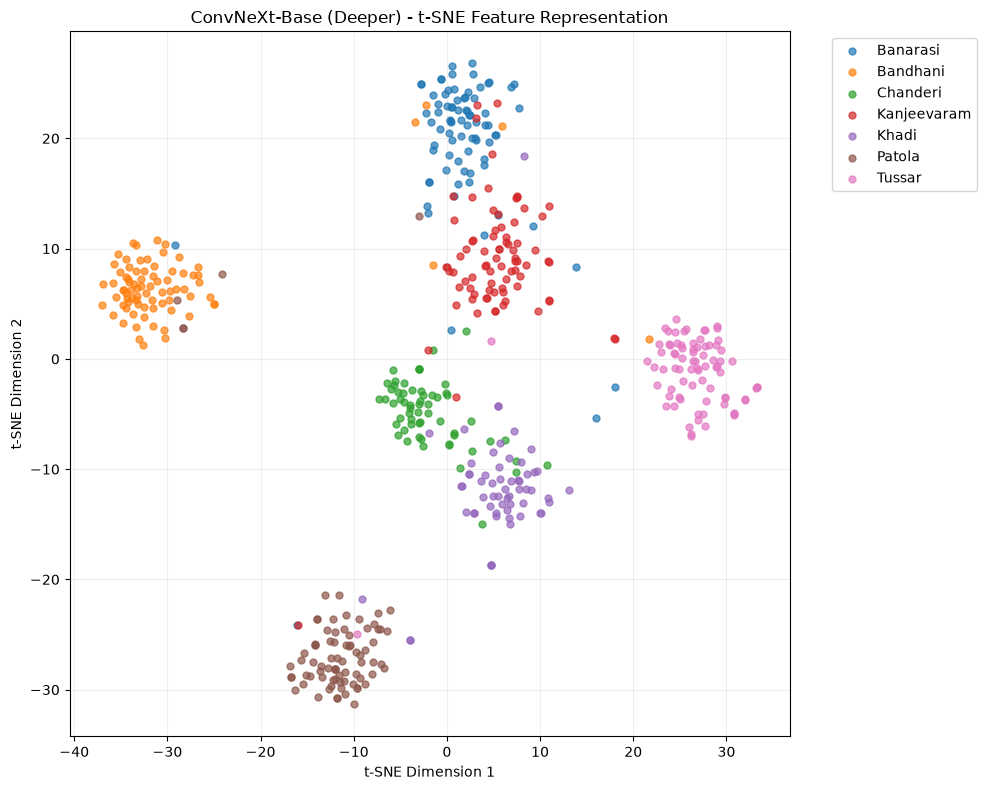

In [45]:
convnext_base_deeper_results=evaluate_model(
    convnext_base_deeper_ema,
    "ConvNeXt-Base (Deeper)"
)

# Model Parameters


In [46]:
!pip install torchinfo -q
from torchinfo import summary

In [47]:
def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return round(total / 1e6, 2), round(trainable / 1e6, 2)

models_for_params = {
    "Swin-Tiny": swin_tiny,
    "Xception (with Attention)": xception,
    "ConvNeXt-Base": convnext_base,
    "ConvNeXt-Base (Deeper)": convnext_base_deeper,
    "ConvNeXt-Base (Stage-3 Deeper)": convnext_base_stage3deeper,
    "HybridWeaveNet": hybrid_weavenet,
}

rows = []
for name, m in models_for_params.items():
    total, trainable = count_params(m)
    rows.append([name, total, trainable])

params_df = pd.DataFrame(rows, columns=["Model", "Total (M)", "Trainable (M)"])
display(params_df)

,Model,Total (M),Trainable (M)
0,Swin-Tiny,27.52,27.52
1,Xception (with Attention),21.35,21.35
2,ConvNeXt-Base,87.57,87.57
3,ConvNeXt-Base (Deeper),103.08,103.08
4,ConvNeXt-Base (Stage-3 Deeper),98.21,98.21
5,HybridWeaveNet,24.91,24.91


# COMPARISION

In [48]:
comparison_df=pd.DataFrame([
    ["Swin-Tiny",swin_results["accuracy"],swin_results["precision"],swin_results["recall"],swin_results["f1"],swin_results["macro_auc"],swin_results["weighted_auc"],swin_results["macro_ap"],swin_results["weighted_ap"]],
    ["Xception (with Attention)",xception_results["accuracy"],xception_results["precision"],xception_results["recall"],xception_results["f1"],xception_results["macro_auc"],xception_results["weighted_auc"],xception_results["macro_ap"],xception_results["weighted_ap"]],
    ["ConvNeXt-Base",convnext_base_results["accuracy"],convnext_base_results["precision"],convnext_base_results["recall"],convnext_base_results["f1"],convnext_base_results["macro_auc"],convnext_base_results["weighted_auc"],convnext_base_results["macro_ap"],convnext_base_results["weighted_ap"]],
    ["ConvNeXt-Base (Deeper)",convnext_base_deeper_results["accuracy"],convnext_base_deeper_results["precision"],convnext_base_deeper_results["recall"],convnext_base_deeper_results["f1"],convnext_base_deeper_results["macro_auc"],convnext_base_deeper_results["weighted_auc"],convnext_base_deeper_results["macro_ap"],convnext_base_deeper_results["weighted_ap"]],
    ["ConvNeXt-Base (Stage-3 Deeper)",convnext_base_stage3deeper_results["accuracy"],convnext_base_stage3deeper_results["precision"],convnext_base_stage3deeper_results["recall"],convnext_base_stage3deeper_results["f1"],convnext_base_stage3deeper_results["macro_auc"],convnext_base_stage3deeper_results["weighted_auc"],convnext_base_stage3deeper_results["macro_ap"],convnext_base_stage3deeper_results["weighted_ap"]],
    ["HybridWeaveNet",hybrid_results["accuracy"],hybrid_results["precision"],hybrid_results["recall"],hybrid_results["f1"],hybrid_results["macro_auc"],hybrid_results["weighted_auc"],hybrid_results["macro_ap"],hybrid_results["weighted_ap"]]
],columns=[
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "Macro-AUC",
    "Weighted-AUC",
    "Macro-AP",
    "Weighted-AP"
])

comparison_df=comparison_df.sort_values(
    "Accuracy",
    ascending=False
).reset_index(drop=True)

comparison_df=comparison_df.merge(params_df[["Model","Total (M)","Trainable (M)"]],on="Model",how="left")

display(comparison_df.round(4))
comparison_df.to_csv("comparison_results_60_20_20.csv", index=False)

,Model,Accuracy,Precision,Recall,F1-Score,Macro-AUC,Weighted-AUC,Macro-AP,Weighted-AP,Total (M),Trainable (M)
0,ConvNeXt-Base (Deeper),0.9192,0.9195,0.9192,0.9190,0.9925,0.9921,0.9643,0.9646,103.08,103.08
1,ConvNeXt-Base (Stage-3 Deeper),0.9154,0.9164,0.9154,0.9152,0.9928,0.9925,0.9643,0.9646,98.21,98.21
2,ConvNeXt-Base,0.9135,0.9138,0.9135,0.9132,0.9918,0.9915,0.9604,0.9606,87.57,87.57
3,Swin-Tiny,0.9135,0.9137,0.9135,0.9132,0.9870,0.9869,0.9533,0.9547,27.52,27.52
4,HybridWeaveNet,0.8923,0.8926,0.8923,0.8921,0.9867,0.9863,0.9378,0.9376,24.91,24.91
5,Xception (with Attention),0.8712,0.8708,0.8712,0.8704,0.9837,0.9834,0.9412,0.9421,21.35,21.35


In [ ]:
import pandas as pd
import torch
from torch.utils.data import DataLoader

# --------------------------------------------------
# 1. Create clean evaluation loaders
# --------------------------------------------------

train_eval_loader = DataLoader(
    FabricDataset(DATA_DIR, train_indices, val_transform),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

val_eval_loader = DataLoader(
    FabricDataset(DATA_DIR, val_indices, val_transform),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_eval_loader = DataLoader(
    FabricDataset(DATA_DIR, test_indices, val_transform),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)


# --------------------------------------------------
# 2. Accuracy calculation function
# --------------------------------------------------

@torch.no_grad()
def calculate_accuracy(model, loader, use_tta=False):

    model = model.to(DEVICE)
    model.eval()

    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(images)

        if use_tta:
            flipped_outputs = model(torch.flip(images, dims=[3]))

            probabilities = (
                torch.softmax(outputs, dim=1) +
                torch.softmax(flipped_outputs, dim=1)
            ) / 2

            predictions = torch.argmax(probabilities, dim=1)

        else:
            predictions = torch.argmax(outputs, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return correct / total


# --------------------------------------------------
# 3. All trained models
# --------------------------------------------------

all_models = {

    "Swin-Tiny": swin_tiny_ema,

    "HybridWeaveNet": hybrid_weavenet_ema,

    "Xception": xception_ema,

    "ConvNeXt-Base": convnext_base_ema,

    "ConvNeXt-Base (Deeper)": convnext_base_deeper_ema,

    "ConvNeXt-Base (Stage3 Deeper)": convnext_base_stage3deeper_ema

}


# --------------------------------------------------
# 4. Calculate Train, Validation and Test Accuracy
# --------------------------------------------------

accuracy_results = []

for model_name, model in all_models.items():

    print(f"Evaluating {model_name}...")

    train_acc = calculate_accuracy(
        model, train_eval_loader
    )

    val_acc = calculate_accuracy(
        model, val_eval_loader
    )

    test_acc = calculate_accuracy(
        model, test_eval_loader, use_tta=True
    )

    accuracy_results.append({

        "Model": model_name,

        "Training Accuracy (%)": round(train_acc * 100, 2),

        "Validation Accuracy (%)": round(val_acc * 100, 2),

        "Testing Accuracy (%)": round(test_acc * 100, 2)

    })


# --------------------------------------------------
# 5. Final Comparison Table
# --------------------------------------------------

accuracy_df = pd.DataFrame(accuracy_results)

print("\n========== ALL MODELS ACCURACY COMPARISON ==========")

display(accuracy_df)

# ABLATION STUDY: Incremental Depth

Starting from the baseline ConvNeXt-Base `[3, 3, 27, 3]`, blocks are added **one stage at a time** until the proposed `[4, 4, 30, 4]` is reached, so the gain of each step can be seen.

| ID | Blocks per stage | Change |
|----|------------------|--------|
| A0 | [3, 3, 27, 3] | Baseline (already trained above) |
| A1 | [4, 3, 27, 3] | +1 block in stage 1 |
| A2 | [4, 4, 27, 3] | +1 block in stage 2 |
| A3 | [4, 4, 30, 3] | +3 blocks in stage 3 |
| A4 | [4, 4, 30, 4] | +1 block in stage 4 = proposed Deeper (already trained above) |

A0 and A4 reuse the models trained above. A1 to A3 are trained here with the same settings as the other ConvNeXt runs (same split, augmentation, sampler, focal loss, EMA, lr 3e-5, patience 7, seed 42).

In [49]:
from timm.models.convnext import ConvNeXtBlock
from sklearn.metrics import roc_auc_score

STAGE_CHANNELS = [128, 256, 512, 1024]

def build_convnext_variant(depths):
    """Same construction as the 'Deeper' cell: pretrained convnext_base, then add/trim blocks per stage."""
    m = timm.create_model("convnext_base", pretrained=True, num_classes=num_classes, drop_path_rate=0.3)
    for stage, ch, target_n in zip(m.stages, STAGE_CHANNELS, depths):
        blocks = list(stage.blocks)
        if target_n > len(blocks):
            blocks += [ConvNeXtBlock(in_chs=ch, out_chs=ch) for _ in range(target_n - len(blocks))]
        elif target_n < len(blocks):
            blocks = blocks[:target_n]
        stage.blocks = nn.Sequential(*blocks)
    return m

@torch.no_grad()
def predict_test(model):
    """Same test-time augmentation as evaluate_model (original + horizontal flip)."""
    model = model.to(DEVICE).eval()
    y_true, y_prob = [], []
    for images, labels in test_loader:
        images = images.to(DEVICE)
        p = (torch.softmax(model(images), 1) + torch.softmax(model(torch.flip(images, dims=[3])), 1)) / 2
        y_true.extend(labels.numpy()); y_prob.extend(p.cpu().numpy())
    y_true, y_prob = np.array(y_true), np.array(y_prob)
    return y_true, y_prob.argmax(1), y_prob

def test_metrics(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "Macro-AUC": roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro"),
    }

In [50]:
# (ID, description, blocks per stage, existing (EMA model, val-acc history) or None -> train now)
ablation_configs = [
    ("A0", "Baseline",                              [3, 3, 27, 3], (convnext_base_ema,          convnext_base_val_acc)),
    ("A1", "+1 block in stage 1",                   [4, 3, 27, 3], None),
    ("A2", "+1 block in stage 2",                   [4, 4, 27, 3], None),
    ("A3", "+3 blocks in stage 3",                  [4, 4, 30, 3], None),
    ("A4", "+1 block in stage 4 (proposed Deeper)", [4, 4, 30, 4], (convnext_base_deeper_ema,    convnext_base_deeper_val_acc)),
]

ablation_results = {}
for tag, desc, depths, existing in ablation_configs:
    if existing is not None:
        ema_model, val_acc = existing
    else:
        print(f"\n===== Training {tag}: {desc} {depths} =====")
        _LR_BACKUP, _PATIENCE_BACKUP = LEARNING_RATE, PATIENCE
        LEARNING_RATE, PATIENCE = 3e-5, 7
        random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
        model = build_convnext_variant(depths)
        model, ema_model, _, _, val_acc = train_model(model, f"ConvNeXt-Base {tag} {depths}")
        LEARNING_RATE, PATIENCE = _LR_BACKUP, _PATIENCE_BACKUP
    y_true, y_pred, y_prob = predict_test(ema_model)
    ablation_results[tag] = {**test_metrics(y_true, y_pred, y_prob),
                             "Params (M)": round(sum(p.numel() for p in ema_model.parameters()) / 1e6, 2),
                             "Best Val Acc": max(val_acc), "Val curve": val_acc}
    if existing is None:
        del model, ema_model
        torch.cuda.empty_cache()


===== Training A1: +1 block in stage 1 [4, 3, 27, 3] =====
ConvNeXt-Base A1 [4, 3, 27, 3] | Epoch 01/50 | Train Loss: 0.9112 | Train Acc: 0.4823 | Val Loss: 1.3281 | Val Acc: 0.2563
ConvNeXt-Base A1 [4, 3, 27, 3] | Epoch 02/50 | Train Loss: 0.5727 | Train Acc: 0.6898 | Val Loss: 1.0136 | Val Acc: 0.4605
ConvNeXt-Base A1 [4, 3, 27, 3] | Epoch 03/50 | Train Loss: 0.4451 | Train Acc: 0.7604 | Val Loss: 0.7512 | Val Acc: 0.6339
ConvNeXt-Base A1 [4, 3, 27, 3] | Epoch 04/50 | Train Loss: 0.4307 | Train Acc: 0.7469 | Val Loss: 0.5674 | Val Acc: 0.7495
ConvNeXt-Base A1 [4, 3, 27, 3] | Epoch 05/50 | Train Loss: 0.3867 | Train Acc: 0.7919 | Val Loss: 0.4471 | Val Acc: 0.8015
ConvNeXt-Base A1 [4, 3, 27, 3] | Epoch 06/50 | Train Loss: 0.3488 | Train Acc: 0.7714 | Val Loss: 0.3696 | Val Acc: 0.8324
ConvNeXt-Base A1 [4, 3, 27, 3] | Epoch 07/50 | Train Loss: 0.3207 | Train Acc: 0.8362 | Val Loss: 0.3201 | Val Acc: 0.8536
ConvNeXt-Base A1 [4, 3, 27, 3] | Epoch 08/50 | Train Loss: 0.3096 | Train Acc: 

In [51]:
rows = []
for tag, desc, depths, _ in ablation_configs:
    r = ablation_results[tag]
    rows.append({"ID": tag, "Change": desc, "Blocks per stage": str(depths), "Total blocks": sum(depths),
                 "Params (M)": r["Params (M)"], "Accuracy": r["Accuracy"], "Precision": r["Precision"],
                 "Recall": r["Recall"], "F1-Score": r["F1-Score"], "Macro-AUC": r["Macro-AUC"],
                 "Best Val Acc": r["Best Val Acc"]})
ablation_df = pd.DataFrame(rows)
ablation_df["Gain vs previous step (pp)"] = (ablation_df["Accuracy"].diff() * 100).round(2)
ablation_df["Gain vs baseline (pp)"] = ((ablation_df["Accuracy"] - ablation_df.loc[0, "Accuracy"]) * 100).round(2)
display(ablation_df.round(4))
ablation_df.to_csv("ablation_depth_incremental.csv", index=False)

,ID,Change,Blocks per stage,Total blocks,Params (M),Accuracy,Precision,Recall,F1-Score,Macro-AUC,Best Val Acc,Gain vs previous step (pp),Gain vs baseline (pp)
0,A0,Baseline,"[3, 3, 27, 3]",36,87.57,0.9135,0.9138,0.9135,0.9132,0.9916,0.9114,NaN,0.00
1,A1,+1 block in stage 1,"[4, 3, 27, 3]",37,87.71,0.9096,0.9105,0.9096,0.9093,0.9922,0.9229,-0.38,-0.38
2,A2,+1 block in stage 2,"[4, 4, 27, 3]",38,88.25,0.9173,0.9174,0.9173,0.9170,0.9924,0.9171,0.77,0.38
3,A3,+3 blocks in stage 3,"[4, 4, 30, 3]",41,94.63,0.9115,0.9119,0.9115,0.9111,0.9907,0.9152,-0.58,-0.19
4,A4,+1 block in stage 4 (proposed Deeper),"[4, 4, 30, 4]",42,103.08,0.9192,0.9195,0.9192,0.9190,0.9922,0.9229,0.77,0.58


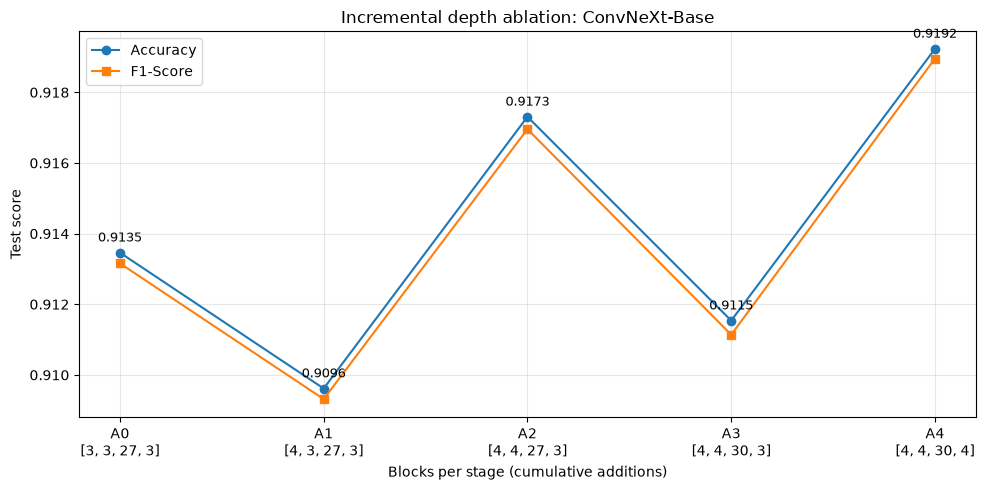

In [52]:
labels = [f"{r['ID']}\n{r['Blocks per stage']}" for _, r in ablation_df.iterrows()]
plt.figure(figsize=(10, 5))
plt.plot(labels, ablation_df["Accuracy"], marker="o", label="Accuracy")
plt.plot(labels, ablation_df["F1-Score"], marker="s", label="F1-Score")
for x, v in enumerate(ablation_df["Accuracy"]):
    plt.annotate(f"{v:.4f}", (x, v), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
plt.xlabel("Blocks per stage (cumulative additions)"); plt.ylabel("Test score")
plt.title("Incremental depth ablation: ConvNeXt-Base"); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.savefig("ablation_depth_incremental.png", dpi=200); plt.show()

# INFERENCE TIME AND MEMORY

Complements the parameter counts (Table II) for the deployment scenario. Single 299 x 299 image, FP32, evaluated EMA weights.

* **GFLOPs** are counted with `torch.utils.flop_counter` (FLOPs = 2 x MACs; GMACs is also given).
* **Latency** is the mean over repeated forward passes after warm-up (GPU timings are synchronised). CPU latency is given because the web application may run without a GPU.
* **Peak GPU memory** is the extra GPU memory needed to hold one copy of the model and run one forward pass.
* **Weights size** is parameters x 4 bytes (FP32).
* Xception + attention is profiled on a freshly built replica of the same architecture, because its attention is attached by a forward hook that does not survive `deepcopy`. FLOPs and latency do not depend on the weights.
* Timings depend on the hardware: report the device name and the CPU thread count with the table.

In [79]:
import time, gc
from torch.utils.flop_counter import FlopCounterMode

N_WARMUP, N_RUNS = 10, 50           # GPU timing repeats
N_WARMUP_CPU, N_RUNS_CPU = 3, 20    # CPU timing repeats (slower)
GPU_BATCH = 32                      # for GPU throughput (images / s); reduce to 8 if you get out-of-memory

_old_cudnn_benchmark = torch.backends.cudnn.benchmark
torch.backends.cudnn.benchmark = False      # avoids autotune spikes in timing and peak memory

def build_profile_models():
    """Fresh replicas of the models (weights do not affect speed / FLOPs / memory)."""
    xcep = timm.create_model("xception", pretrained=False, num_classes=num_classes)
    xcep = attach_attention(xcep, xcep.act4, channels=2048)
    return {
        "Swin-Tiny": timm.create_model("swin_tiny_patch4_window7_224", pretrained=False, num_classes=num_classes, img_size=IMG_SIZE),
        "Xception (with Attention)": xcep,
        "ConvNeXt-Base": build_convnext_variant([3, 3, 27, 3]),
        "ConvNeXt-Base (Deeper) - Proposed": build_convnext_variant([4, 4, 30, 4]),
        "ConvNeXt-Base (Stage-3 Deeper)": build_convnext_variant([3, 3, 32, 3]),
        "HybridWeaveNet": HybridWeaveNet(num_classes=num_classes, pretrained=False),
    }

def count_gflops(model):
    model = model.to("cpu").eval()
    x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
    with FlopCounterMode(display=False) as fc, torch.no_grad():
        model(x)
    flops = fc.get_total_flops()
    return flops / 1e9, flops / 2e9   # GFLOPs (2 x MACs), GMACs

@torch.no_grad()
def cpu_latency(model, n_warmup=N_WARMUP_CPU, n_runs=N_RUNS_CPU):
    model = model.to("cpu").eval()
    x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
    for _ in range(n_warmup): model(x)
    t = []
    for _ in range(n_runs):
        s = time.perf_counter(); model(x); t.append((time.perf_counter() - s) * 1000)
    return float(np.mean(t)), float(np.std(t))

@torch.no_grad()
def gpu_metrics(model, n_warmup=N_WARMUP, n_runs=N_RUNS):
    torch.cuda.empty_cache(); torch.cuda.synchronize()
    base_mem = torch.cuda.memory_allocated()
    model = model.to("cuda").eval()
    x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device="cuda")
    for _ in range(n_warmup): model(x)
    torch.cuda.synchronize()

    # peak memory = weights + activations of ONE forward pass, measured after warm-up
    torch.cuda.reset_peak_memory_stats()
    model(x); torch.cuda.synchronize()
    peak_mb = (torch.cuda.max_memory_allocated() - base_mem) / 1024**2

    # latency, batch 1
    t = []
    for _ in range(n_runs):
        s = time.perf_counter(); model(x); torch.cuda.synchronize(); t.append((time.perf_counter() - s) * 1000)

    # throughput with a batch
    xb = torch.randn(GPU_BATCH, 3, IMG_SIZE, IMG_SIZE, device="cuda")
    for _ in range(3): model(xb)
    torch.cuda.synchronize(); s = time.perf_counter()
    for _ in range(10): model(xb)
    torch.cuda.synchronize()
    fps = GPU_BATCH * 10 / (time.perf_counter() - s)

    model.to("cpu"); torch.cuda.empty_cache()
    return float(np.mean(t)), float(np.std(t)), peak_mb, fps

print("CPU threads:", torch.get_num_threads())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

rows = []
for name, m in build_profile_models().items():
    print("Profiling", name, "...")
    try:
        params = sum(p.numel() for p in m.parameters()) / 1e6
        gflops, gmacs = count_gflops(m)
        cpu_ms, cpu_sd = cpu_latency(m)
        row = {"Model": name, "Params (M)": params, "Weights size (MB, FP32)": params * 4,
               "GFLOPs": gflops, "GMACs": gmacs,
               "CPU latency (ms/img)": cpu_ms, "CPU latency std (ms)": cpu_sd}
        if torch.cuda.is_available():
            g_ms, g_sd, peak, fps = gpu_metrics(m)
            row.update({"GPU latency (ms/img)": g_ms, "GPU latency std (ms)": g_sd,
                        "GPU throughput (img/s)": fps, "Peak GPU memory (MB)": peak})
        rows.append(row)
    except Exception as e:
        print(f"  {name} failed:", repr(e))
    del m; gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

torch.backends.cudnn.benchmark = _old_cudnn_benchmark     # restore the notebook's original setting

efficiency_df = pd.DataFrame(rows)
display(efficiency_df.round(3))
efficiency_df.to_csv("inference_time_memory.csv", index=False)

CPU threads: 36
GPU: NVIDIA RTX 4500 Ada Generation


f:\New folder\envs\gpuenv\Lib\site-packages\timm\models\_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


EfficientNetV2-RW-S feature channels: 1792
Profiling Swin-Tiny ...
Profiling Xception (with Attention) ...
Profiling ConvNeXt-Base ...
Profiling ConvNeXt-Base (Deeper) - Proposed ...
Profiling ConvNeXt-Base (Stage-3 Deeper) ...
Profiling HybridWeaveNet ...


,Model,Params (M),"Weights size (MB, FP32)",GFLOPs,GMACs,CPU latency (ms/img),CPU latency std (ms),GPU latency (ms/img),GPU latency std (ms),GPU throughput (img/s),Peak GPU memory (MB)
0,Swin-Tiny,27.525,110.099,18.429,9.214,45.375,4.208,20.088,9.557,358.789,140.537
1,Xception (with Attention),21.346,85.383,16.713,8.356,55.870,6.857,11.959,6.799,496.627,139.790
2,ConvNeXt-Base,87.574,350.295,51.260,25.630,85.716,13.466,12.184,3.469,238.670,368.776
3,ConvNeXt-Base (Deeper) - Proposed,103.080,412.319,59.726,29.863,81.906,3.929,13.426,3.176,203.405,426.995
4,ConvNeXt-Base (Stage-3 Deeper),98.208,392.832,58.136,29.068,78.844,2.493,13.099,3.767,216.031,409.153
5,HybridWeaveNet,24.914,99.657,10.993,5.496,55.210,4.409,18.284,4.805,613.773,118.539


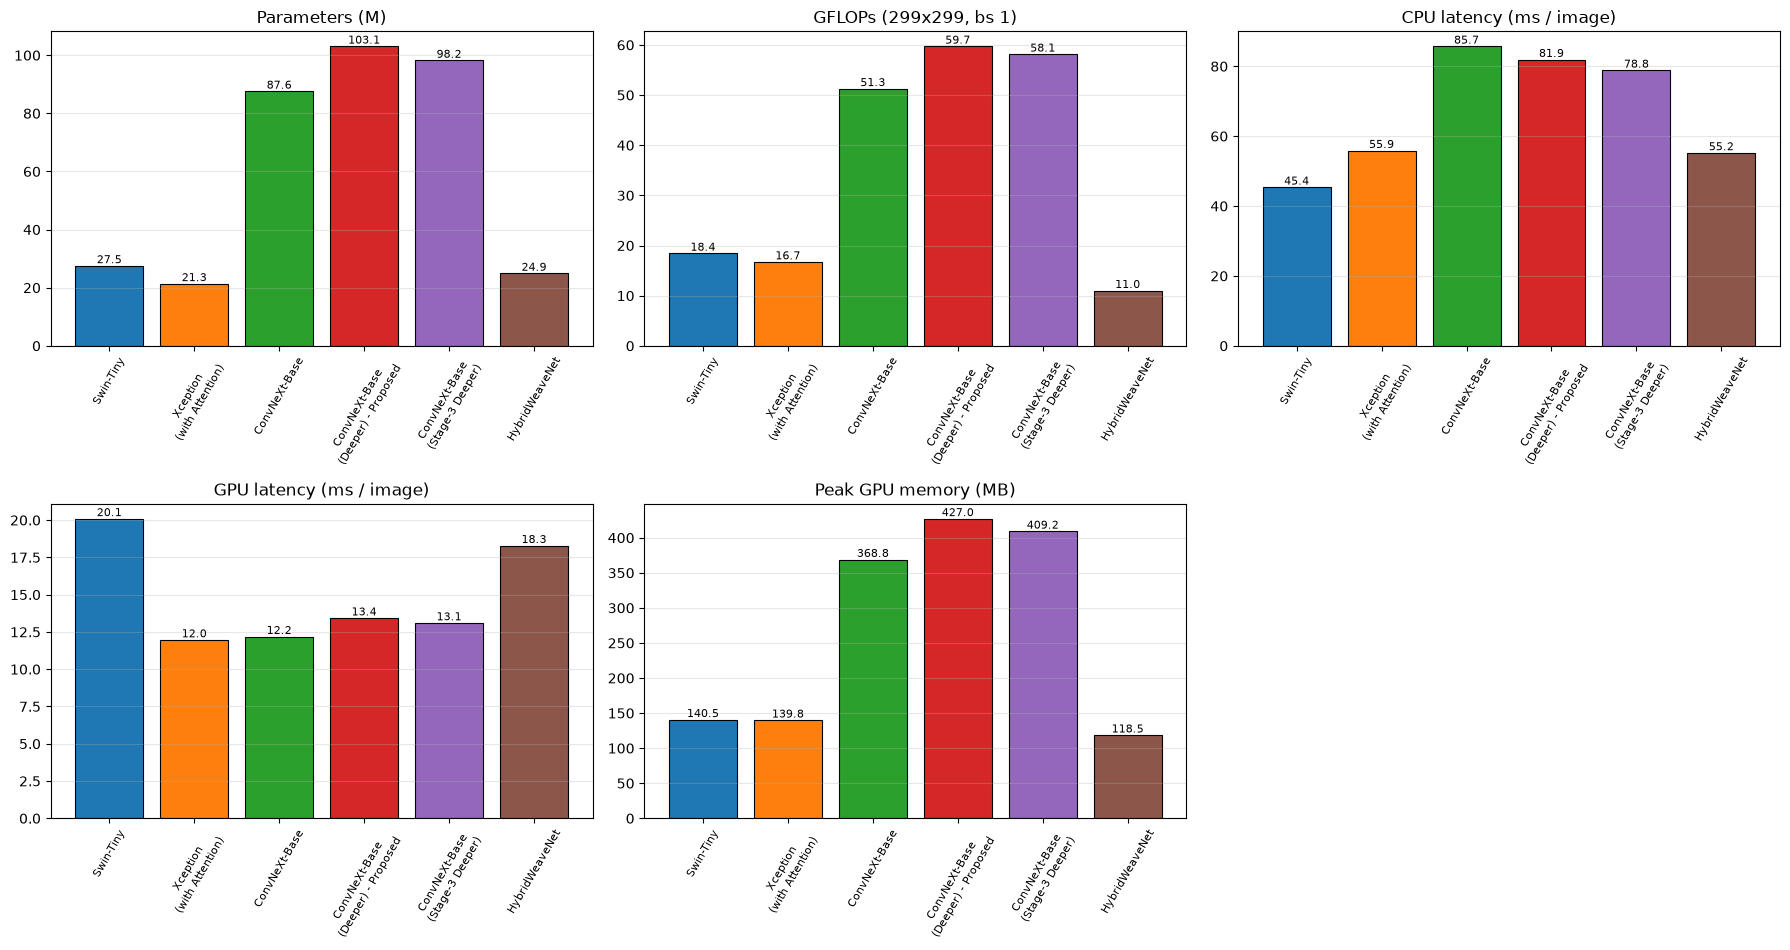

In [80]:
# ---- Graphs for inference time / memory ----
panels = [("Params (M)", "Parameters (M)"), ("GFLOPs", "GFLOPs (299x299, bs 1)"), ("CPU latency (ms/img)", "CPU latency (ms / image)")]
if "GPU latency (ms/img)" in efficiency_df.columns:
    panels += [("GPU latency (ms/img)", "GPU latency (ms / image)"), ("Peak GPU memory (MB)", "Peak GPU memory (MB)")]
ncols = 3; nrows = int(np.ceil(len(panels) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4.8 * nrows))
axes = np.atleast_1d(axes).ravel()
cols = plt.cm.tab10(np.arange(len(efficiency_df)))
names = efficiency_df["Model"].str.replace(" (", "\n(", regex=False)
for ax, (col, title) in zip(axes, panels):
    bars = ax.bar(names, efficiency_df[col], color=cols, edgecolor="black", linewidth=0.8)
    for b_, v in zip(bars, efficiency_df[col]):
        ax.text(b_.get_x() + b_.get_width() / 2, v, f"{v:,.1f}", ha="center", va="bottom", fontsize=8)
    ax.set_title(title); ax.tick_params(axis="x", rotation=60, labelsize=8); ax.grid(axis="y", alpha=0.3)
for ax in axes[len(panels):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig("inference_time_memory.png", dpi=200); plt.show()

In [67]:
comparison_df=pd.DataFrame([
    ["Swin-Tiny",swin_results["accuracy"],swin_results["precision"],swin_results["recall"],swin_results["f1"],swin_results["macro_auc"],swin_results["weighted_auc"],swin_results["macro_ap"],swin_results["weighted_ap"]],
    ["Xception (with Attention)",xception_results["accuracy"],xception_results["precision"],xception_results["recall"],xception_results["f1"],xception_results["macro_auc"],xception_results["weighted_auc"],xception_results["macro_ap"],xception_results["weighted_ap"]],
    ["ConvNeXt-Base",convnext_base_results["accuracy"],convnext_base_results["precision"],convnext_base_results["recall"],convnext_base_results["f1"],convnext_base_results["macro_auc"],convnext_base_results["weighted_auc"],convnext_base_results["macro_ap"],convnext_base_results["weighted_ap"]],
    ["ConvNeXt-Base (Deeper)",convnext_base_deeper_results["accuracy"],convnext_base_deeper_results["precision"],convnext_base_deeper_results["recall"],convnext_base_deeper_results["f1"],convnext_base_deeper_results["macro_auc"],convnext_base_deeper_results["weighted_auc"],convnext_base_deeper_results["macro_ap"],convnext_base_deeper_results["weighted_ap"]],
    ["ConvNeXt-Base (Stage-3 Deeper)",convnext_base_stage3deeper_results["accuracy"],convnext_base_stage3deeper_results["precision"],convnext_base_stage3deeper_results["recall"],convnext_base_stage3deeper_results["f1"],convnext_base_stage3deeper_results["macro_auc"],convnext_base_stage3deeper_results["weighted_auc"],convnext_base_stage3deeper_results["macro_ap"],convnext_base_stage3deeper_results["weighted_ap"]],
    ["HybridWeaveNet",hybrid_results["accuracy"],hybrid_results["precision"],hybrid_results["recall"],hybrid_results["f1"],hybrid_results["macro_auc"],hybrid_results["weighted_auc"],hybrid_results["macro_ap"],hybrid_results["weighted_ap"]]
],columns=[
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "Macro-AUC",
    "Weighted-AUC",
    "Macro-AP",
    "Weighted-AP"
])

comparison_df=comparison_df.sort_values(
    "Accuracy",
    ascending=False
).reset_index(drop=True)

comparison_df=comparison_df.merge(params_df[["Model","Total (M)","Trainable (M)"]],on="Model",how="left")

display(comparison_df.round(4))
comparison_df.to_csv("comparison_results_60_20_20.csv", index=False)

,Model,Accuracy,Precision,Recall,F1-Score,Macro-AUC,Weighted-AUC,Macro-AP,Weighted-AP,Total (M),Trainable (M)
0,ConvNeXt-Base (Deeper),0.9192,0.9195,0.9192,0.9190,0.9925,0.9921,0.9643,0.9646,103.08,103.08
1,ConvNeXt-Base (Stage-3 Deeper),0.9154,0.9164,0.9154,0.9152,0.9928,0.9925,0.9643,0.9646,98.21,98.21
2,ConvNeXt-Base,0.9135,0.9138,0.9135,0.9132,0.9918,0.9915,0.9604,0.9606,87.57,87.57
3,Swin-Tiny,0.9135,0.9137,0.9135,0.9132,0.9870,0.9869,0.9533,0.9547,27.52,27.52
4,HybridWeaveNet,0.8923,0.8926,0.8923,0.8921,0.9867,0.9863,0.9378,0.9376,24.91,24.91
5,Xception (with Attention),0.8712,0.8708,0.8712,0.8704,0.9837,0.9834,0.9412,0.9421,21.35,21.35


# Modelling

In [68]:
import os
os.makedirs("model", exist_ok=True)

torch.save(convnext_base_deeper_ema.state_dict(), "model/model_best_own.pth")

# Graph

In [69]:
import matplotlib.pyplot as plt
import numpy as np

models=comparison_df["Model"].tolist()

colors=plt.cm.tab10(
    np.linspace(0,1,len(models))
)

def plot_metric(metric,title,ylabel):
    values=comparison_df[metric].values

    plt.figure(figsize=(12,7))

    bars=plt.bar(
        models,
        values,
        color=colors,
        edgecolor="black",
        linewidth=0.8
    )

    for bar,value in zip(bars,values):
        plt.text(
            bar.get_x()+bar.get_width()/2,
            value+0.01,
            f"{value:.4f}",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold"
        )

    plt.title(
        title,
        fontsize=15,
        fontweight="bold"
    )

    plt.xlabel(
        "Model",
        fontsize=12
    )

    plt.ylabel(
        ylabel,
        fontsize=12
    )

    plt.ylim(
        0,
        1.08
    )

    plt.xticks(
        rotation=45,
        ha="right"
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()
    plt.show()

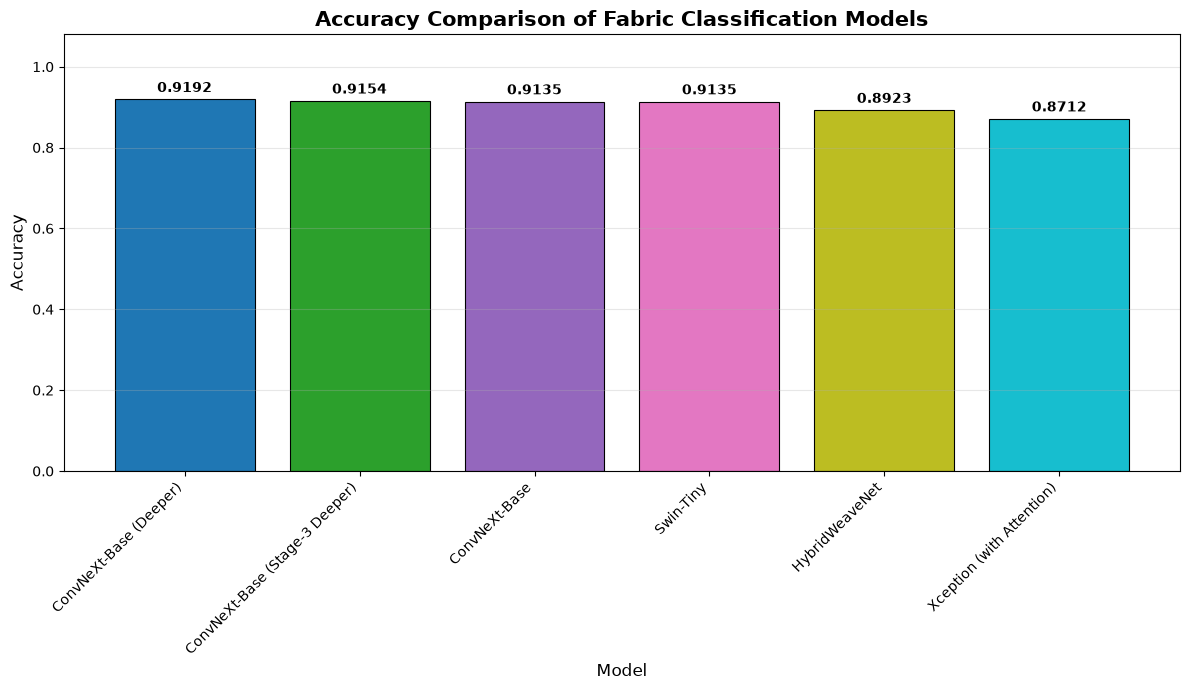

In [70]:
plot_metric(
    "Accuracy",
    "Accuracy Comparison of Fabric Classification Models",
    "Accuracy"
)

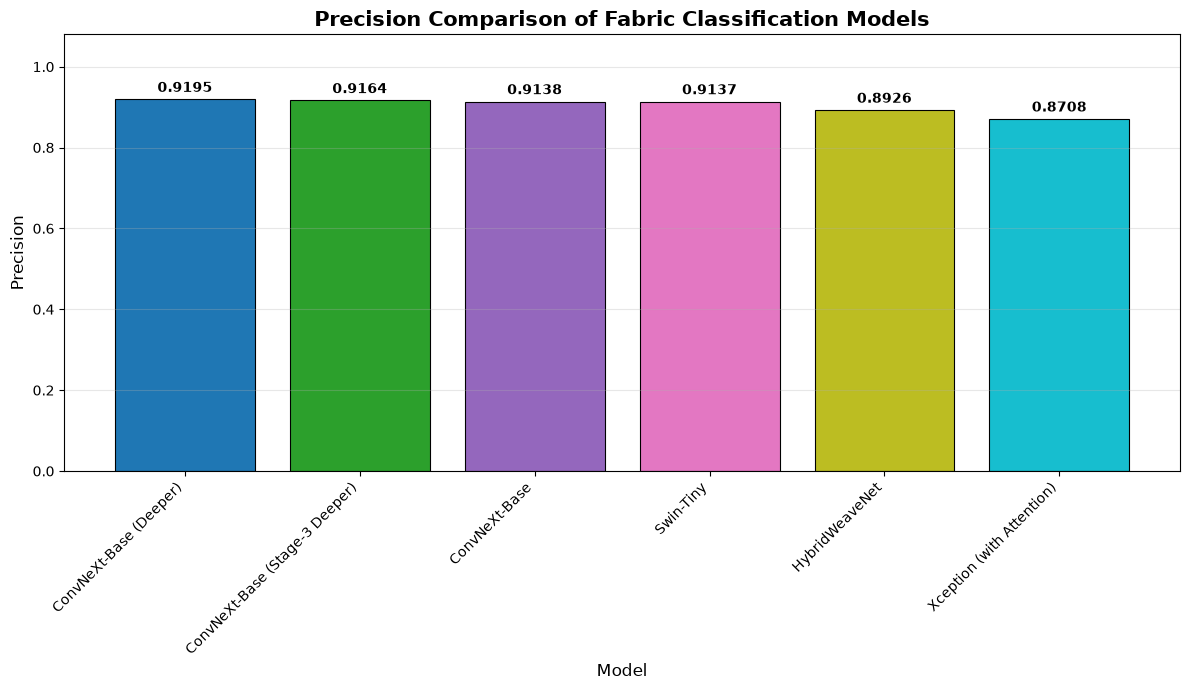

In [71]:
plot_metric(
    "Precision",
    "Precision Comparison of Fabric Classification Models",
    "Precision"
)

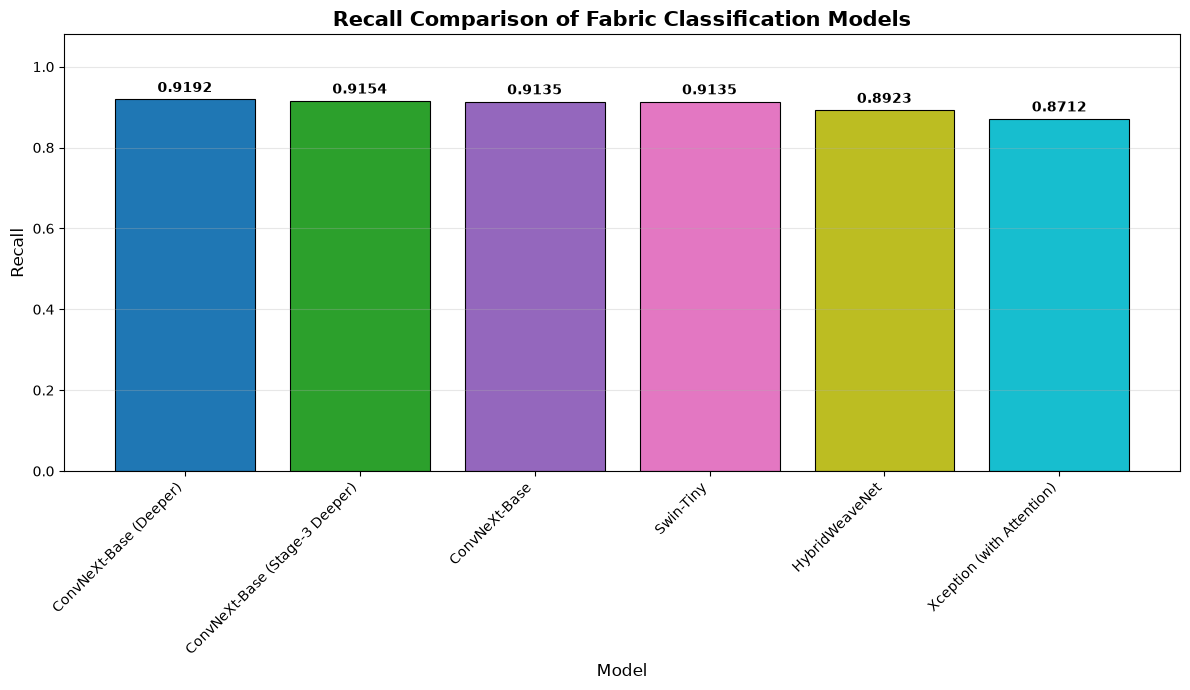

In [72]:
plot_metric(
    "Recall",
    "Recall Comparison of Fabric Classification Models",
    "Recall"
)

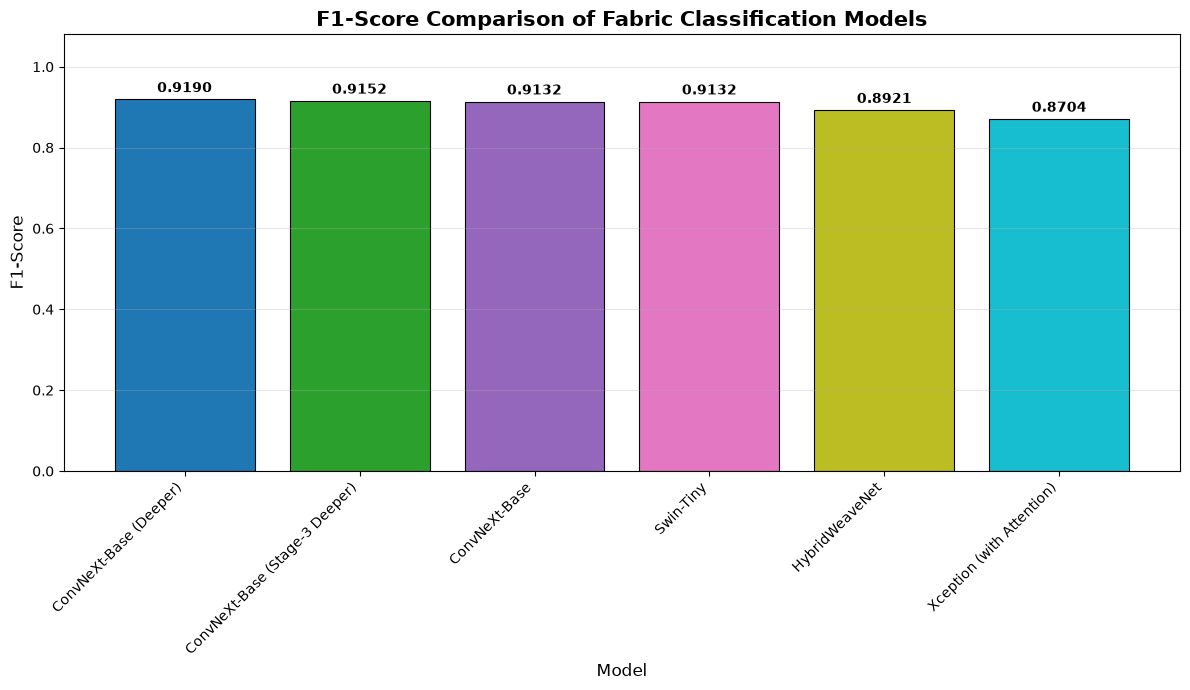

In [73]:
plot_metric(
    "F1-Score",
    "F1-Score Comparison of Fabric Classification Models",
    "F1-Score"
)

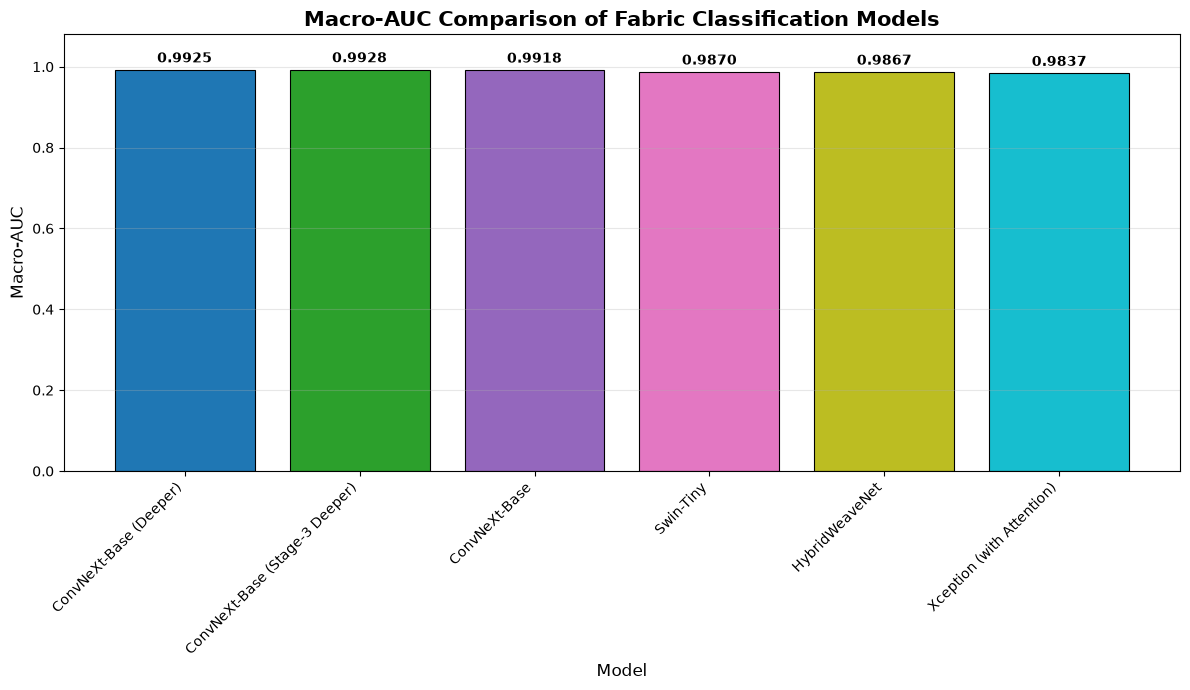

In [74]:
plot_metric(
    "Macro-AUC",
    "Macro-AUC Comparison of Fabric Classification Models",
    "Macro-AUC"
)

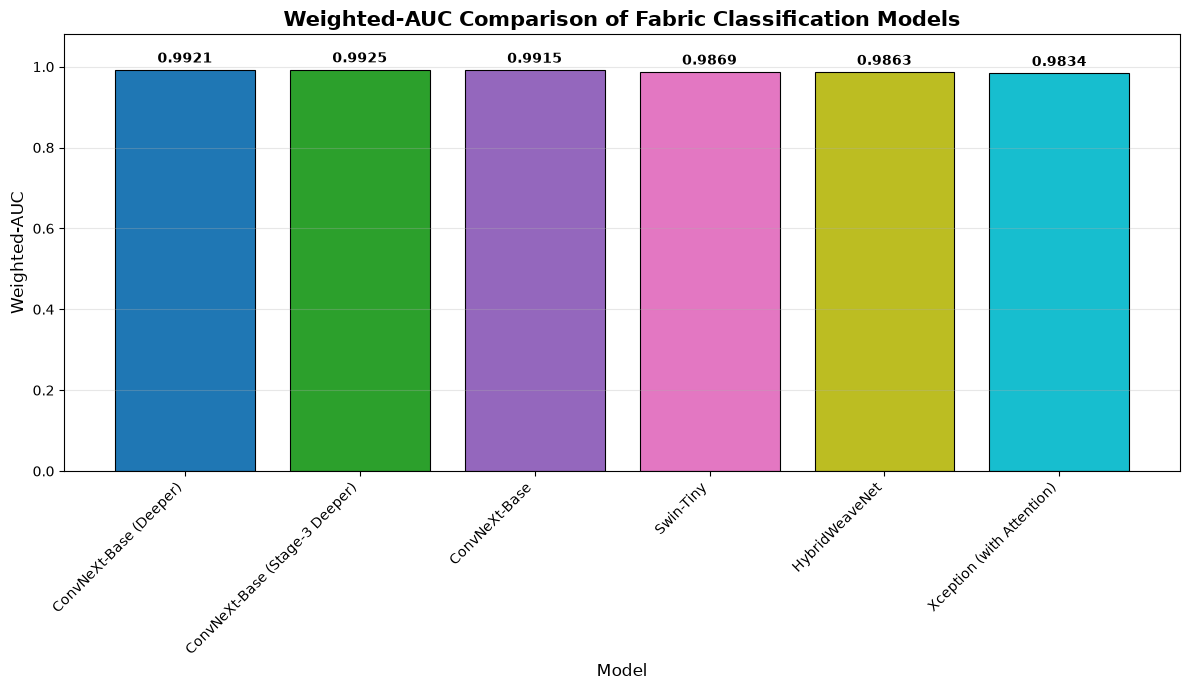

In [75]:
plot_metric(
    "Weighted-AUC",
    "Weighted-AUC Comparison of Fabric Classification Models",
    "Weighted-AUC"
)

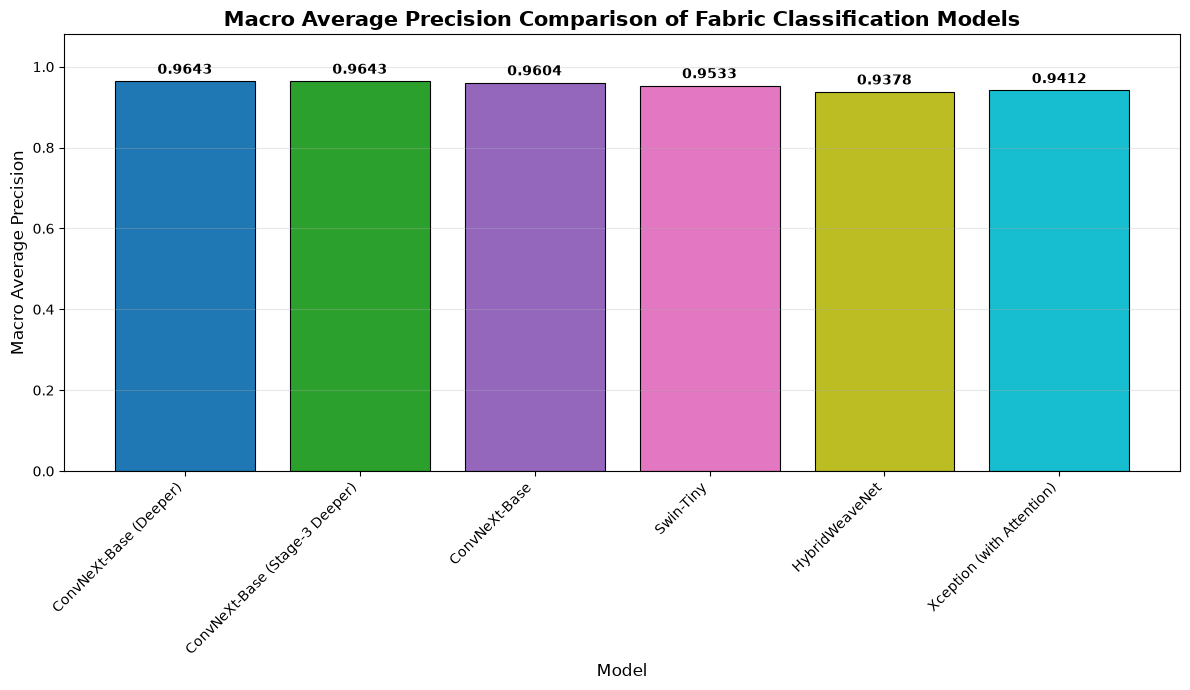

In [76]:
plot_metric(
    "Macro-AP",
    "Macro Average Precision Comparison of Fabric Classification Models",
    "Macro Average Precision"
)

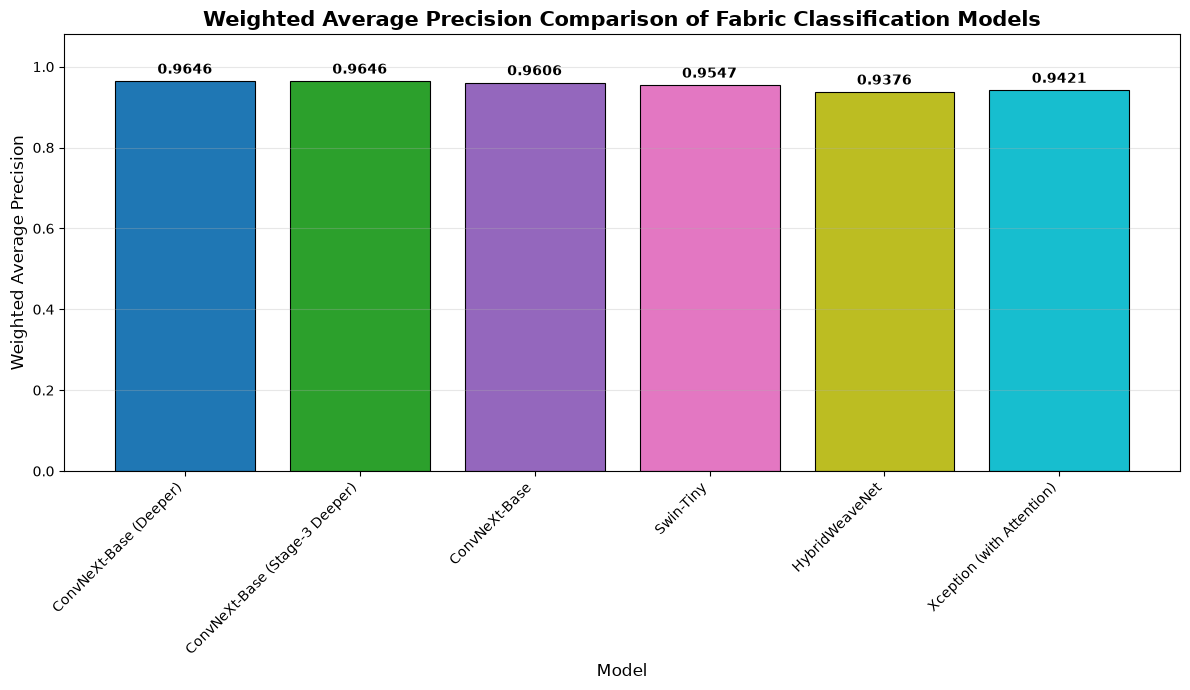

In [77]:
plot_metric(
    "Weighted-AP",
    "Weighted Average Precision Comparison of Fabric Classification Models",
    "Weighted Average Precision"
)

In [78]:
with open("convnext_base_deeper_layer_params.txt", "w") as f:
    total_params = 0
    f.write(f"ConvNeXt-Base (Deeper) — Layer-wise Parameters\n{'='*90}\n")
    for name, param in convnext_base_deeper.named_parameters():
        num_params = param.numel()
        total_params += num_params
        f.write(f"{name:<60}{str(tuple(param.shape)):<20}{num_params:>10,}\n")
    f.write(f"{'-'*90}\nTOTAL: {total_params:,}\n")

print("Saved to convnext_base_deeper_layer_params.txt")

Saved to convnext_base_deeper_layer_params.txt
